# 🌳 Kruskal na prática
### Árvore Geradora Mínima, do grafo dos slides às ruas de Natal

**DCA3702 · Algoritmos e Estrutura de Dados II** · DCA/UFRN · Prof. Ivanovitch Silva

> 💡 Imagine que você vai passar cabos de internet entre todos os prédios da UFRN. Todos os prédios precisam ficar conectados, o comprimento total de cabo deve ser o menor possível e não pode existir cabo sobrando, indo e voltando à toa. Esse é o problema da **Árvore Geradora Mínima** (*Minimum Spanning Tree*, MST). O algoritmo de **Kruskal** resolve o problema com uma ideia surpreendentemente simples. Ele pega sempre a conexão mais barata disponível e só recusa as que fechariam um ciclo.

Neste notebook você vai **ver** o algoritmo funcionando quadro a quadro, **mexer** nos pesos para testar a sua intuição e depois **levar o Kruskal para a cidade**, usando a malha viária real de Natal baixada do OpenStreetMap com a biblioteca [OSMnx](https://osmnx.readthedocs.io/).

| Parte | Tema | O que você leva |
|:---:|---|---|
| 0 | Preparação | bibliotecas e a paleta visual do notebook |
| 1 | O problema | o grafo dos slides e **todas** as suas árvores geradoras |
| 2 | Union-Find | como detectar um ciclo em tempo quase constante |
| 3 | Kruskal passo a passo | a mesma sequência dos slides, agora animada |
| 4 | Laboratórios | mude pesos e grafos e veja a MST reagir |
| 5 | Complexidade | O(E log E) medido no cronômetro |
| 6 | Natal I · Tirol | a MST da malha viária de um bairro e as ruas críticas |
| 7 | Natal II · Hospitais | a rede mínima que liga os hospitais da cidade |
| 8 | Laboratório da cidade | escolha qualquer categoria de lugar e rode tudo de novo |
| 9 | Agrupamento | cortar a MST para dividir a cidade em regiões |
| 10 | Desafios | três resolvidos para estudo e cinco em aberto |

---
## Parte 0 · Preparação

🎯 Instalar o OSMnx, importar as bibliotecas e definir a paleta de cores que dá significado às figuras.

O Colab já traz NetworkX, Plotly, Folium, ipywidgets e scikit-learn. Só falta o OSMnx.

In [1]:
!pip install -q osmnx

In [2]:
import math
import random
import time
import warnings
from collections import defaultdict

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
import plotly.graph_objects as go
import folium
import ipywidgets as widgets
from ipywidgets import interact_manual
from IPython.display import display, HTML
import geopandas as gpd
from shapely.geometry import MultiPoint, LineString
import osmnx as ox

warnings.filterwarnings("ignore")

# Configurações do OSMnx
ox.settings.use_cache = True          # guarda as respostas do OpenStreetMap em disco
ox.settings.log_console = False
ox.settings.requests_timeout = 300    # a cidade inteira pode demorar

print(f"OSMnx {ox.__version__} · NetworkX {nx.__version__}")

OSMnx 2.1.1 · NetworkX 3.7


### 🎨 A paleta do notebook

🧠 Pelo princípio da **similaridade**, se uma cor sempre significa a mesma coisa, o leitor para de decodificar a legenda e passa a enxergar o significado direto. Por isso a paleta é definida **uma única vez** aqui e reutilizada por todas as figuras. O azul dos vértices e o vermelho da MST são os mesmos dos slides da aula.

In [3]:
PALETA = {
    "no":          "#1f6fc5",   # azul dos vértices (igual aos slides)
    "mst":         "#e03131",   # vermelho, a aresta ESTÁ na MST
    "analise":     "#f59f00",   # âmbar, a aresta está sendo analisada agora
    "rejeitada":   "#adb5bd",   # cinza claro pontilhado, a aresta fecharia um ciclo
    "pendente":    "#495057",   # cinza escuro, ainda não foi analisada
    "isolado":     "#adb5bd",   # vértice que ainda está sozinho no seu conjunto
    "fundo_claro": "#eaf2fb",   # lembra o fundo azul claro dos slides
    "fundo_escuro":"#0d1117",   # fundo dos mapas (figura e fundo)
    "malha":       "#30363d",   # ruas no mapa, apagadas de propósito
    "texto":       "#212529",
}

# Cores para distinguir CONJUNTOS do Union-Find e GRUPOS (sem vermelho e sem âmbar,
# que já têm significado próprio)
CORES_GRUPOS = ["#1f6fc5", "#2f9e44", "#9c36b5", "#0c8599", "#5c940d",
                "#364fc7", "#a61e4d", "#e8590c", "#087f5b", "#862e9c"]
CORES_GRUPOS_ESCURO = ["#4dabf7", "#69db7c", "#da77f2", "#3bc9db", "#a9e34b",
                       "#748ffc", "#f783ac", "#ffa94d", "#63e6be", "#e599f7"]


def fmt(x, casas=1):
    """Formata números no padrão brasileiro (1.234,5)."""
    s = f"{x:,.{casas}f}"
    return s.replace(",", "§").replace(".", ",").replace("§", ".")


def painel(titulo, metricas, cor=None):
    """Mostra métricas lado a lado num cartão (proximidade, o que é relacionado fica junto)."""
    cor = cor or PALETA["mst"]
    itens = "".join(
        f"<div style='flex:1;min-width:130px;padding:10px 12px;border-radius:10px;"
        f"background:#ffffff;border:1px solid #dee2e6'>"
        f"<div style='font-size:12px;color:#6c757d'>{k}</div>"
        f"<div style='font-size:20px;font-weight:700;color:#212529'>{v}</div></div>"
        for k, v in metricas.items())
    display(HTML(
        f"<div style='border-left:6px solid {cor};padding:10px 14px;margin:8px 0;"
        f"background:#f8f9fa;border-radius:8px'>"
        f"<div style='font-weight:700;margin-bottom:8px;color:#212529'>{titulo}</div>"
        f"<div style='display:flex;gap:10px;flex-wrap:wrap'>{itens}</div></div>"))


def mostrar_paleta():
    significados = [("mst", "está na MST"), ("analise", "em análise agora"),
                    ("rejeitada", "rejeitada (fecharia ciclo)"), ("pendente", "ainda não analisada"),
                    ("no", "vértice")]
    blocos = "".join(
        f"<div style='display:flex;align-items:center;gap:8px;margin-right:18px'>"
        f"<span style='display:inline-block;width:34px;height:8px;border-radius:4px;background:{PALETA[c]}'></span>"
        f"<span style='font-size:13px;color:#212529'>{t}</span></div>" for c, t in significados)
    display(HTML(f"<div style='display:flex;flex-wrap:wrap;padding:10px;background:{PALETA['fundo_claro']};"
                 f"border-radius:8px'>{blocos}</div>"))


mostrar_paleta()

---
## Parte 1 · O problema e o grafo dos slides

🎯 Reconstruir o exemplo da aula e entender por que precisamos de um algoritmo esperto.

🧠 **Árvore geradora.** Dado um grafo conectado, não direcionado e com pesos não negativos, uma árvore geradora é um subconjunto de arestas que

1. alcança **todos** os vértices,
2. mantém tudo **conectado**,
3. **não tem ciclos**.

Uma consequência importante é que toda árvore geradora de um grafo com $V$ vértices tem exatamente $V - 1$ arestas. A **Árvore Geradora Mínima** é, entre todas as árvores geradoras, a que tem a **menor soma de pesos**.

Nos slides o grafo é guardado como **lista de adjacência**. Para cada vértice existe uma lista de pares `[vizinho, peso]`. O código abaixo é o mesmo dos slides. Ele transforma a lista de adjacência numa lista de arestas `[origem, destino, peso]` e ordena pelo peso.

In [4]:
# Lista de adjacência dos slides, edges[v] = [[vizinho, peso], ...]
edges = [
    [[4, 3], [3, 4]],                   # Vértice 0
    [[2, 5], [3, 7]],                   # Vértice 1
    [[1, 5], [3, 6], [4, 8]],           # Vértice 2
    [[0, 4], [1, 7], [2, 6], [4, 2]],   # Vértice 3
    [[3, 2], [0, 3], [2, 8]],           # Vértice 4
]

edgeList = []
for sourceIndex, vertex in enumerate(edges):
    for edge in vertex:
        if edge[0] > sourceIndex:       # evita duplicatas, cada aresta aparece 2 vezes na adjacência
            edgeList.append([sourceIndex, edge[0], edge[1]])

sortedEdges = sorted(edgeList, key=lambda edge: edge[2])

print("Arestas ordenadas por peso (igual ao slide 'Sort the Edges by Weight')\n")
for u, v, w in sortedEdges:
    print(f"   [{u}, {v}, {w}],   # Weight {w}")

Arestas ordenadas por peso (igual ao slide 'Sort the Edges by Weight')

   [3, 4, 2],   # Weight 2
   [0, 4, 3],   # Weight 3
   [0, 3, 4],   # Weight 4
   [1, 2, 5],   # Weight 5
   [2, 3, 6],   # Weight 6
   [1, 3, 7],   # Weight 7
   [2, 4, 8],   # Weight 8


Agora guardamos o mesmo grafo num objeto do NetworkX, com as posições dos vértices copiadas do desenho dos slides. Assim cada figura deste notebook fica com a mesma cara da aula (similaridade entre slide e código).

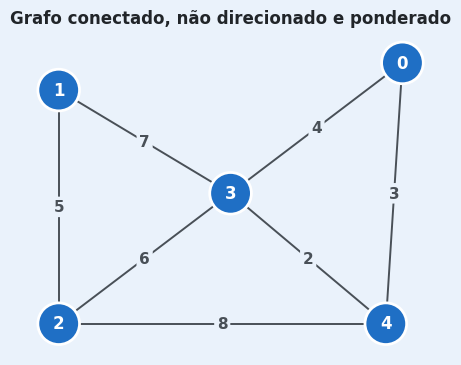

In [5]:
G_toy = nx.Graph()
G_toy.add_weighted_edges_from(edgeList)

# posições aproximadas do desenho dos slides
POS_TOY = {0: (3.55, 2.55), 1: (0.45, 2.30), 2: (0.45, 0.15), 3: (2.00, 1.35), 4: (3.40, 0.15)}


def estilizar_eixo(ax, cor_fundo):
    ax.set_facecolor(cor_fundo)
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)


def desenhar_grafo(G, pos, ax, mst=(), titulo="", cor_fundo=None, mostrar_pesos=True,
                   tamanho_no=900, cor_nos=None, fonte=11):
    """Desenha um grafo pequeno no estilo dos slides. Arestas da MST em vermelho."""
    cor_fundo = cor_fundo or PALETA["fundo_claro"]
    mst = {frozenset((a[0], a[1])) for a in mst}
    estilizar_eixo(ax, cor_fundo)
    for u, v, d in G.edges(data=True):
        na_mst = frozenset((u, v)) in mst
        cor = PALETA["mst"] if na_mst else PALETA["pendente"]
        ax.plot(*zip(pos[u], pos[v]), color=cor, lw=3.4 if na_mst else 1.4,
                zorder=1, solid_capstyle="round")
        if mostrar_pesos and "weight" in d:
            xm, ym = (pos[u][0] + pos[v][0]) / 2, (pos[u][1] + pos[v][1]) / 2
            ax.text(xm, ym, f"{d['weight']:g}", ha="center", va="center", fontsize=fonte,
                    fontweight="bold", color=cor, zorder=2,
                    bbox=dict(boxstyle="round,pad=0.18", fc=cor_fundo, ec="none"))
    nos = list(G.nodes())
    cores = [(cor_nos or {}).get(n, PALETA["no"]) for n in nos]
    ax.scatter([pos[n][0] for n in nos], [pos[n][1] for n in nos], s=tamanho_no, c=cores,
               edgecolors="white", linewidths=2, zorder=3)
    for n in nos:
        ax.text(*pos[n], str(n), ha="center", va="center", color="white",
                fontsize=fonte + 1, fontweight="bold", zorder=4)
    ax.set_title(titulo, fontsize=12, fontweight="bold", color=PALETA["texto"])
    ax.margins(0.12)


fig, ax = plt.subplots(figsize=(5.5, 4.2), facecolor=PALETA["fundo_claro"])
desenhar_grafo(G_toy, POS_TOY, ax, titulo="Grafo conectado, não direcionado e ponderado")
plt.show()

### 👀 Quantas árvores geradoras cabem nesse grafo?

Antes de qualquer algoritmo, vamos usar a força bruta. O NetworkX tem um iterador que gera **todas** as árvores geradoras em ordem crescente de custo (`nx.SpanningTreeIterator`). Para um grafo de 5 vértices isso é instantâneo e nos dá uma visão completa do espaço de busca.

Na galeria abaixo, todas as miniaturas usam o mesmo desenho (similaridade), então o olho compara só o que muda, ou seja, quais arestas foram escolhidas. A primeira miniatura, com moldura vermelha, é a MST.

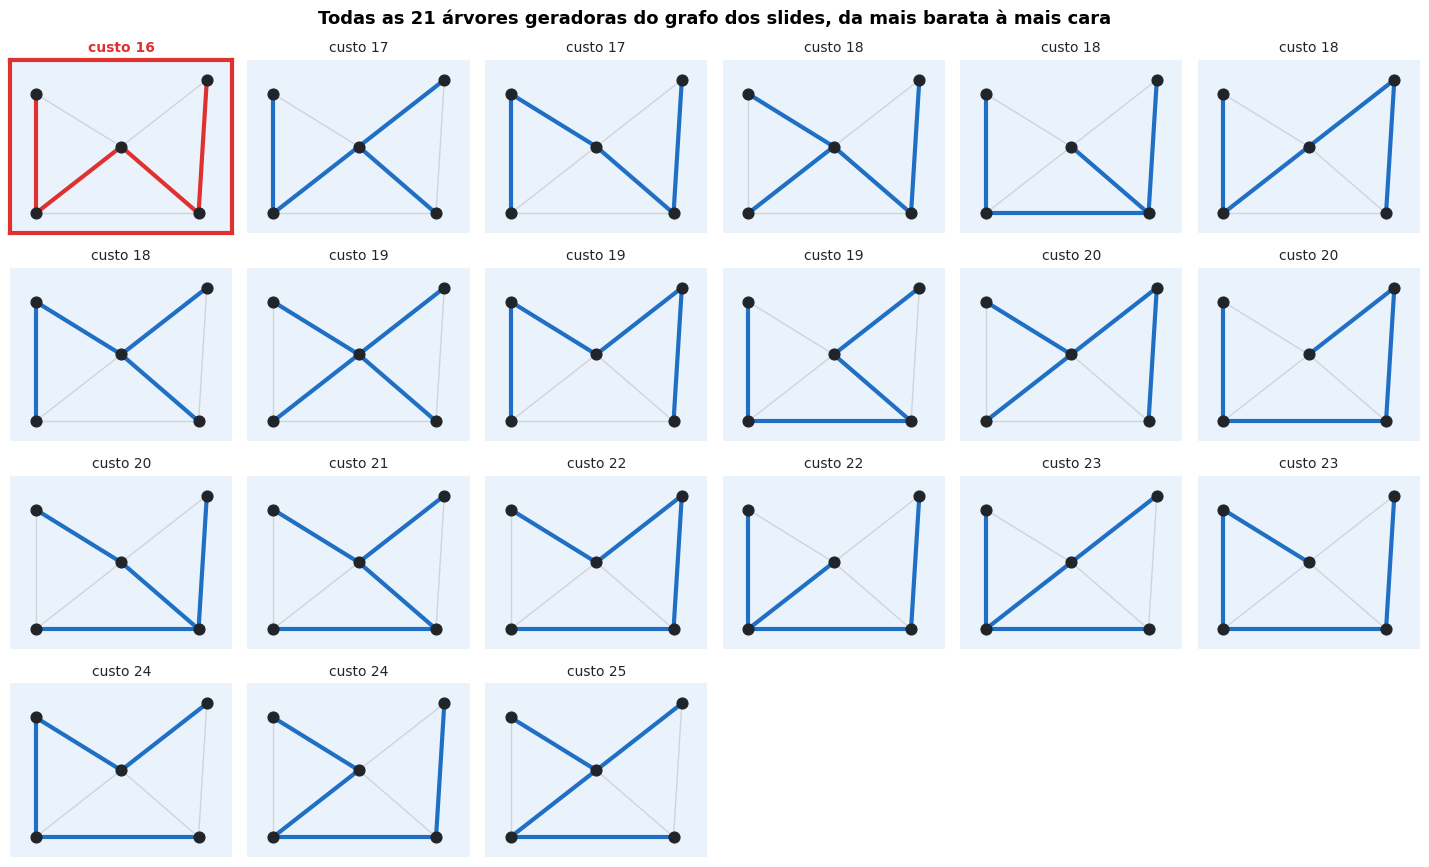

In [6]:
arvores = list(nx.SpanningTreeIterator(G_toy, weight="weight", minimum=True))
custos = [T.size(weight="weight") for T in arvores]

ncol = 6
nlin = math.ceil(len(arvores) / ncol)
fig, eixos = plt.subplots(nlin, ncol, figsize=(2.4 * ncol, 2.2 * nlin), facecolor="white")
for i, ax in enumerate(np.ravel(eixos)):
    if i >= len(arvores):
        ax.axis("off")
        continue
    T = arvores[i]
    estilizar_eixo(ax, PALETA["fundo_claro"])
    for u, v in G_toy.edges():                     # fundo, o grafo inteiro bem apagado
        ax.plot(*zip(POS_TOY[u], POS_TOY[v]), color="#ced4da", lw=1, zorder=1)
    cor = PALETA["mst"] if i == 0 else PALETA["no"]
    for u, v in T.edges():                         # figura, a árvore escolhida
        ax.plot(*zip(POS_TOY[u], POS_TOY[v]), color=cor, lw=3, zorder=2, solid_capstyle="round")
    ax.scatter(*zip(*POS_TOY.values()), s=60, c=PALETA["texto"], zorder=3)
    ax.set_title(f"custo {custos[i]:g}", fontsize=10, color=cor if i == 0 else PALETA["texto"],
                 fontweight="bold" if i == 0 else "normal")
    ax.margins(0.15)
    if i == 0:
        for s in ax.spines.values():
            s.set_visible(True); s.set_color(PALETA["mst"]); s.set_linewidth(3)
fig.suptitle(f"Todas as {len(arvores)} árvores geradoras do grafo dos slides, da mais barata à mais cara",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

painel("Espaço de busca do grafo dos slides", {
    "Árvores geradoras": len(arvores),
    "Custo mínimo (MST)": f"{min(custos):g}",
    "Custo máximo": f"{max(custos):g}",
    "Arestas por árvore (V − 1)": G_toy.number_of_nodes() - 1,
})

⚠️ **Por que não usar força bruta sempre?** Para 5 vértices dá para olhar uma árvore por uma. Para um grafo **completo** com $n$ vértices, a fórmula de Cayley diz que existem $n^{\,n-2}$ árvores geradoras. A célula abaixo mostra o tamanho desse número.

In [7]:
for n in [5, 10, 20, 50, 100]:
    total = n ** (n - 2)
    print(f"n = {n:>3} vértices  →  {total:.3e} árvores geradoras")
print("\nPara comparar, estima-se que o universo observável tenha cerca de 1e80 átomos.")

n =   5 vértices  →  1.250e+02 árvores geradoras
n =  10 vértices  →  1.000e+08 árvores geradoras
n =  20 vértices  →  2.621e+23 árvores geradoras
n =  50 vértices  →  3.553e+81 árvores geradoras
n = 100 vértices  →  1.000e+196 árvores geradoras

Para comparar, estima-se que o universo observável tenha cerca de 1e80 átomos.


Com 50 vértices já passamos do número de átomos do universo. Precisamos de uma estratégia que **construa** a MST diretamente, sem enumerar nada. É aí que entra o Kruskal, e para ele funcionar precisamos de uma estrutura auxiliar que responda muito rápido a uma pergunta. Essa estrutura é o assunto da próxima parte.

---
## Parte 2 · Union-Find, o detector de ciclos

🎯 Entender como saber, em tempo quase constante, se uma aresta fecharia um ciclo.

🧠 A estratégia do Kruskal é percorrer as arestas da mais leve para a mais pesada e aceitar cada uma, **a menos que ela feche um ciclo**. A pergunta que precisamos responder milhares de vezes é a do slide *How can we identify a cycle?*

> Adicionar a aresta $(u, v)$ cria um ciclo **se e somente se** $u$ e $v$ já estiverem conectados pelas arestas aceitas até agora.

Então basta manter os vértices agrupados em **conjuntos disjuntos** (cada conjunto é um pedaço já conectado da floresta) e oferecer duas operações.

| Operação | O que faz |
|---|---|
| `find(x)` | devolve o **representante** do conjunto de `x`. Dois vértices estão no mesmo conjunto se têm o mesmo representante |
| `union(a, b)` | funde os conjuntos de `a` e `b` num só |

Essa estrutura se chama **Union-Find** ou **DSU** (*Disjoint Set Union*). Vamos implementar três versões, da mais ingênua à mais eficiente, para ver na Parte 5 a diferença que isso faz.

| Versão | `find` | `union` | Ideia |
|---|---|---|---|
| Quick-Find | $O(1)$ | $O(V)$ | cada vértice guarda um **rótulo**, como os números laranja dos slides. Unir exige reescrever rótulos |
| Quick-Union ingênuo | $O(V)$ no pior caso | $O(V)$ | cada vértice aponta para um **pai** e o representante é a raiz. Unir é só pendurar uma raiz na outra, mas as árvores podem virar listas compridas |
| Union-Find otimizado | $\approx O(1)$ amortizado | $\approx O(1)$ amortizado | **união por tamanho** (a árvore menor é pendurada na maior) e **compressão de caminho** (todo `find` achata o caminho percorrido) |

O custo amortizado da versão otimizada é $O(\alpha(V))$, onde $\alpha$ é a inversa da função de Ackermann. Para qualquer grafo que caiba no universo, $\alpha(V) \le 4$. Na prática, é constante.

Cada classe conta as operações elementares em `self.ops`, para podermos comparar o trabalho feito por cada uma.

In [8]:
class QuickFind:
    """Cada vértice guarda o rótulo do seu conjunto (os números laranja dos slides).
    find é O(1), mas union precisa varrer TODOS os vértices para reescrever rótulos."""
    nome = "Quick-Find (rótulos)"

    def __init__(self, elementos):
        self.rotulo = {x: x for x in elementos}
        self.ops = 0

    def find(self, x):
        self.ops += 1
        return self.rotulo[x]

    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)
        if ra == rb:
            return False                      # já estavam juntos
        for x in self.rotulo:                 # O(V), percorre todo mundo
            self.ops += 1
            if self.rotulo[x] == ra:
                self.rotulo[x] = rb           # o conjunto de a recebe o rótulo de b
        return True


class QuickUnionIngenuo:
    """Cada vértice aponta para um pai e o representante é a raiz da árvore.
    Sem nenhum cuidado, as árvores podem ficar altas e o find fica lento."""
    nome = "Quick-Union ingênuo"

    def __init__(self, elementos):
        self.pai = {x: x for x in elementos}
        self.ops = 0

    def find(self, x):
        self.ops += 1
        while self.pai[x] != x:               # sobe até a raiz
            x = self.pai[x]
            self.ops += 1
        return x

    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)
        if ra == rb:
            return False
        self.pai[ra] = rb                     # pendura uma raiz na outra, sem critério
        return True


class UnionFind:
    """Union-Find com união por tamanho e compressão de caminho.
    Custo amortizado por operação O(α(V)), na prática constante."""
    nome = "Union-Find otimizado"

    def __init__(self, elementos):
        self.pai = {x: x for x in elementos}
        self.tamanho = {x: 1 for x in elementos}   # quantos elementos cada raiz representa
        self.ops = 0

    def find(self, x):
        # 1) sobe até a raiz
        raiz = x
        self.ops += 1
        while self.pai[raiz] != raiz:
            raiz = self.pai[raiz]
            self.ops += 1
        # 2) compressão de caminho, todos no caminho passam a apontar direto para a raiz
        while self.pai[x] != raiz:
            proximo = self.pai[x]
            self.pai[x] = raiz
            x = proximo
        return raiz

    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)
        if ra == rb:
            return False
        if self.tamanho[ra] < self.tamanho[rb]:    # união por tamanho, a árvore menor vai para baixo
            ra, rb = rb, ra
        self.pai[rb] = ra
        self.tamanho[ra] += self.tamanho[rb]
        return True

    def conjuntos(self):
        grupos = defaultdict(list)
        for x in self.pai:
            grupos[self.find(x)].append(x)
        return dict(grupos)


# Teste rápido, as três versões precisam concordar
for Classe in (QuickFind, QuickUnionIngenuo, UnionFind):
    uf = Classe(range(5))
    respostas = [uf.union(3, 4), uf.union(0, 4), uf.union(0, 3), uf.union(1, 2), uf.union(2, 3)]
    print(f"{Classe.nome:<24} union devolveu {respostas}")

Quick-Find (rótulos)     union devolveu [True, True, False, True, True]
Quick-Union ingênuo      union devolveu [True, True, False, True, True]
Union-Find otimizado     union devolveu [True, True, False, True, True]


👀 As três versões dão a mesma resposta. A terceira chamada, `union(0, 3)`, devolve `False` porque 0 e 3 já estavam no mesmo conjunto. É exatamente a aresta `[0, 3, 4]` que os slides marcam com um ❌.

### 🔬 O que o Union-Find guarda por dentro

Os slides mostram os **rótulos** de cada vértice (a visão do Quick-Find). A versão otimizada guarda outra coisa, uma **floresta de ponteiros** em que cada vértice aponta para o seu pai. A figura abaixo desenha essas árvores internas depois de cada união feita pelo Kruskal no grafo dos slides. Uma seta vai do filho para o pai, e o vértice com anel é a raiz, ou seja, o representante devolvido por `find`.

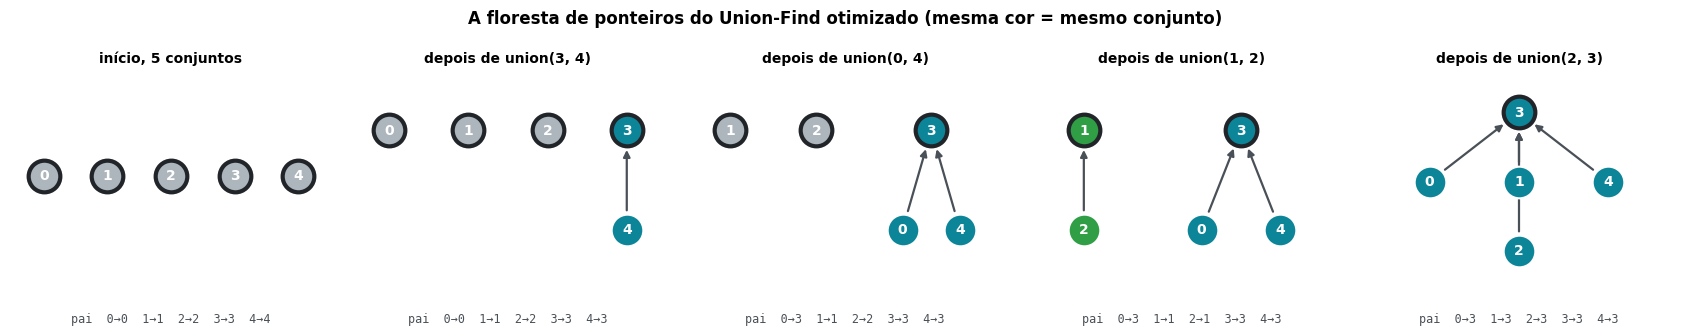

In [9]:
def layout_floresta(pai):
    """Posições (x, y) para desenhar a floresta de ponteiros do Union-Find."""
    filhos = defaultdict(list)
    raizes = []
    for x, p in pai.items():
        (raizes if x == p else filhos[p]).append(x)
    pos, proximo_x = {}, [0]

    def visita(no, prof):
        for f in sorted(filhos[no]):
            visita(f, prof + 1)
        if filhos[no]:
            xs = [pos[f][0] for f in filhos[no]]
            pos[no] = (sum(xs) / len(xs), -prof)
        else:
            pos[no] = (proximo_x[0], -prof)
            proximo_x[0] += 1

    for r in sorted(raizes):
        visita(r, 0)
        proximo_x[0] += 0.5
    return pos, raizes


def desenhar_floresta(uf, ax, titulo):
    pos, raizes = layout_floresta(uf.pai)
    estilizar_eixo(ax, "white")
    comp = {x: uf.find(x) for x in uf.pai}
    tam = defaultdict(int)
    for r in comp.values():
        tam[r] += 1
    for x, p in uf.pai.items():
        if x != p:
            ax.annotate("", xy=pos[p], xytext=pos[x],
                        arrowprops=dict(arrowstyle="-|>", color="#495057", lw=1.6,
                                        shrinkA=14, shrinkB=14))
    for x, (px, py) in pos.items():
        r = comp[x]
        cor = CORES_GRUPOS[r % len(CORES_GRUPOS)] if tam[r] > 1 else PALETA["isolado"]
        ax.scatter(px, py, s=520, c=cor, edgecolors=PALETA["texto"] if x in raizes else "white",
                   linewidths=3 if x in raizes else 1.5, zorder=3)
        ax.text(px, py, str(x), ha="center", va="center", color="white", fontweight="bold", zorder=4)
    ax.set_title(titulo, fontsize=10, fontweight="bold")
    ax.set_xlim(-0.8, max(p[0] for p in pos.values()) + 0.8)
    ax.set_ylim(min(p[1] for p in pos.values()) - 0.7, 0.6)
    texto_pai = "  ".join(f"{x}→{p}" for x, p in sorted(uf.pai.items()))
    ax.text(0.5, -0.06, "pai  " + texto_pai, transform=ax.transAxes, ha="center", va="top",
            fontsize=8.5, family="monospace", color="#495057")


uf_demo = UnionFind(range(5))
unioes = [(3, 4), (0, 4), (1, 2), (2, 3)]        # as quatro arestas que o Kruskal aceita nos slides
fig, eixos = plt.subplots(1, 5, figsize=(17, 3.4))
desenhar_floresta(uf_demo, eixos[0], "início, 5 conjuntos")
for ax, (a, b) in zip(eixos[1:], unioes):
    uf_demo.union(a, b)
    desenhar_floresta(uf_demo, ax, f"depois de union({a}, {b})")
fig.suptitle("A floresta de ponteiros do Union-Find otimizado (mesma cor = mesmo conjunto)",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

👀 Repare em três detalhes.

* **Similaridade.** A cor de um vértice indica o conjunto, a mesma convenção da animação da Parte 3.
* **União por tamanho.** Em `union(2, 3)` a árvore pequena {1, 2} foi pendurada debaixo da árvore maior {0, 3, 4}, e não o contrário. Como um vértice só desce de nível quando o seu conjunto pelo menos dobra de tamanho, a altura nunca passa de $\log_2 V$.
* **Altura máxima 2.** Mesmo com os 5 vértices juntos, qualquer `find` dá no máximo 2 passos até a raiz. Com compressão de caminho, o próximo `find` de um vértice profundo já o deixa pendurado direto na raiz.

---
## Parte 3 · Kruskal passo a passo

🎯 Implementar o algoritmo e assistir a ele tomar cada decisão, na mesma sequência dos slides.

🧠 **O algoritmo inteiro cabe em quatro linhas.**

```text
1. ordene as arestas por peso crescente                       O(E log E)
2. crie um Union-Find com cada vértice sozinho                O(V)
3. para cada aresta (u, v, w) nessa ordem
       se find(u) ≠ find(v)   aceite a aresta e faça union(u, v)
       senão                  descarte, ela fecharia um ciclo
4. pare quando a árvore tiver V − 1 arestas
```

🧠 **Por que ser guloso dá certo?** Pela **propriedade do corte**. Divida os vértices em dois lados quaisquer. A aresta mais leve que atravessa essa divisão sempre pertence a alguma MST, porque se uma árvore usasse uma travessia mais pesada, bastaria trocá-la pela mais leve e o custo cairia. Quando o Kruskal aceita $(u, v)$, ela é a aresta mais leve que sai do conjunto de $u$ (todas as mais leves já foram vistas e ou entraram ou ficaram dentro de um conjunto). Então cada escolha gulosa é segura.

In [10]:
def kruskal(vertices, arestas, uf_classe=UnionFind, parar_cedo=True):
    """
    Algoritmo de Kruskal.

    vertices   iterável com os vértices do grafo
    arestas    lista de tuplas (u, v, peso)
    uf_classe  qual implementação de Union-Find usar (Parte 2)
    parar_cedo encerra assim que a árvore tem V - 1 arestas

    Devolve (mst, custo), onde mst é a lista de arestas (u, v, peso)
    na ORDEM em que foram aceitas.
    """
    vertices = list(vertices)
    uf = uf_classe(vertices)
    ordenadas = sorted(arestas, key=lambda a: a[2])     # passo 1
    mst, custo = [], 0
    alvo = len(vertices) - 1
    for u, v, w in ordenadas:                           # passo 3
        if uf.union(u, v):                              # find(u) != find(v), então une
            mst.append((u, v, w))
            custo += w
            if parar_cedo and len(mst) == alvo:         # passo 4
                break
    return mst, custo


mst_toy, custo_toy = kruskal(G_toy.nodes(), edgeList)
print("Arestas da MST, na ordem em que entraram", mst_toy)
print("Custo total", custo_toy)

Arestas da MST, na ordem em que entraram [(3, 4, 2), (0, 4, 3), (1, 2, 5), (2, 3, 6)]
Custo total 16


Para **visualizar** o algoritmo precisamos de mais informação do que a resposta final. A função abaixo roda o mesmo Kruskal, mas registra o estado completo a cada passo. Ela guarda o resultado de `find(u)` e `find(v)`, a decisão tomada, os conjuntos depois do passo e, quando a aresta é rejeitada, **o caminho que já ligava u a v**. Esse caminho mais a aresta rejeitada formam exatamente o ciclo que estamos evitando.

Aqui usamos `parar_cedo=False` de propósito, para analisar as 7 arestas como nos slides.

In [11]:
def kruskal_rastreado(vertices, arestas):
    """Kruskal que guarda o estado de cada passo, para tabelas e animações."""
    vertices = list(vertices)
    uf = UnionFind(vertices)
    floresta = nx.Graph()
    floresta.add_nodes_from(vertices)
    passos, custo = [], 0
    for i, (u, v, w) in enumerate(sorted(arestas, key=lambda a: a[2]), start=1):
        raizes_antes = {x: uf.find(x) for x in vertices}
        ru, rv = raizes_antes[u], raizes_antes[v]
        if ru != rv:
            uf.union(u, v)
            floresta.add_edge(u, v)
            custo += w
            decisao, ciclo = "aceita", []
        else:
            decisao = "rejeitada"
            ciclo = nx.shortest_path(floresta, u, v)    # o caminho que já existia
        grupos = sorted((sorted(c) for c in uf.conjuntos().values()), key=lambda c: c[0])
        passos.append(dict(
            passo=i, u=u, v=v, w=w, find_u=ru, find_v=rv, decisao=decisao, ciclo=ciclo,
            raizes_antes=raizes_antes, raizes_depois={x: uf.find(x) for x in vertices},
            conjuntos="  ".join("{" + ", ".join(map(str, c)) + "}" for c in grupos),
            custo=custo, n_mst=floresta.number_of_edges()))
    return passos


passos_toy = kruskal_rastreado(G_toy.nodes(), edgeList)

tabela = pd.DataFrame([{
    "Passo": p["passo"],
    "Aresta [u, v, w]": f"[{p['u']}, {p['v']}, {p['w']}]",
    "find(u)": p["find_u"],
    "find(v)": p["find_v"],
    "Decisão": "✔ entra na MST" if p["decisao"] == "aceita" else "✘ fecharia ciclo " + "-".join(map(str, p["ciclo"] + [p["ciclo"][0]])),
    "Conjuntos depois do passo": p["conjuntos"],
    "Custo acumulado": p["custo"],
} for p in passos_toy]).set_index("Passo")


def colorir_linha(linha):
    if linha["Decisão"].startswith("✔"):
        estilo = f"background-color:#fff0f0;color:{PALETA['mst']};font-weight:600"
    else:
        estilo = "background-color:#f1f3f5;color:#868e96"
    return [estilo] * len(linha)


display(tabela.style.apply(colorir_linha, axis=1))

,"Aresta [u, v, w]",find(u),find(v),Decisão,Conjuntos depois do passo,Custo acumulado
Passo,,,,,,
1,"[3, 4, 2]",3,4,✔ entra na MST,"{0} {1} {2} {3, 4}",2
2,"[0, 4, 3]",0,3,✔ entra na MST,"{0, 3, 4} {1} {2}",5
3,"[0, 3, 4]",3,3,✘ fecharia ciclo 0-4-3-0,"{0, 3, 4} {1} {2}",5
4,"[1, 2, 5]",1,2,✔ entra na MST,"{0, 3, 4} {1, 2}",10
5,"[2, 3, 6]",1,3,✔ entra na MST,"{0, 1, 2, 3, 4}",16
6,"[1, 3, 7]",3,3,✘ fecharia ciclo 1-2-3-1,"{0, 1, 2, 3, 4}",16
7,"[2, 4, 8]",3,3,✘ fecharia ciclo 2-3-4-2,"{0, 1, 2, 3, 4}",16


### 🎬 A animação

A tabela é precisa, mas a animação é mais memorável. Ela reproduz a sequência dos slides com **dois quadros por aresta**. No quadro **a**, a aresta está em análise (âmbar) e a seta aponta para ela na lista ordenada. No quadro **b**, a decisão aparece.

* 🔴 **Aceita.** A aresta fica vermelha e, por **destino comum**, todos os vértices dos dois conjuntos passam a ter a mesma cor no mesmo instante.
* ⚪ **Rejeitada.** A aresta vira pontilhado com um ✕, e o caminho que já ligava as duas pontas acende em âmbar. Pelo princípio do **fechamento**, o olho completa o ciclo sozinho e entende na hora por que ela não pode entrar.

O número pequeno ao lado de cada vértice é `find(v)`, o representante do conjunto, no papel dos números laranja dos slides. Use ▶ para tocar ou arraste o controle deslizante para ir e voltar.

In [12]:
def animar_kruskal(G, pos, passos, altura=560):
    """Animação Plotly do Kruskal, com o grafo à esquerda e a lista ordenada à direita."""
    m = len(passos)
    nos = list(G.nodes())
    total_mst = len(nos) - 1

    # ---------- 1) estados que viram quadros ----------
    estados = [dict(status=["pendente"] * m, atual=None, ciclo=[], raizes={x: x for x in nos},
                    rotulo="início",
                    titulo="Início · arestas ordenadas por peso, cada vértice é o seu próprio conjunto")]
    status = ["pendente"] * m
    for i, p in enumerate(passos):
        s = status.copy(); s[i] = "analise"
        mesmo = p["find_u"] == p["find_v"]
        estados.append(dict(
            status=s, atual=i, ciclo=[], raizes=p["raizes_antes"], rotulo=f"{p['passo']}a",
            titulo=(f"Passo {p['passo']}a · aresta [{p['u']}, {p['v']}, {p['w']}] · "
                    f"find({p['u']}) = {p['find_u']} e find({p['v']}) = {p['find_v']} → "
                    + ("mesmo conjunto" if mesmo else "conjuntos diferentes"))))
        status[i] = "mst" if p["decisao"] == "aceita" else "rejeitada"
        if p["decisao"] == "aceita":
            titulo = (f"Passo {p['passo']}b · ✔ aceita, union({p['u']}, {p['v']}) funde os conjuntos · "
                      f"custo {p['custo']} · {p['n_mst']} de {total_mst} arestas")
        else:
            caminho = "-".join(map(str, p["ciclo"]))
            titulo = (f"Passo {p['passo']}b · ✘ rejeitada, {p['u']} e {p['v']} já estão ligados por "
                      f"{caminho} e a aresta fecharia um ciclo")
        estados.append(dict(status=status.copy(), atual=i, rotulo=f"{p['passo']}b",
                            ciclo=p["ciclo"] if p["decisao"] == "rejeitada" else [],
                            raizes=p["raizes_depois"], titulo=titulo))
    estados.append(dict(status=status.copy(), atual=None, ciclo=[], raizes=passos[-1]["raizes_depois"],
                        rotulo="fim",
                        titulo=f"Fim · MST com {total_mst} arestas e custo total {passos[-1]['custo']}"))

    estilo = {  # (cor, largura, traço) de cada status de aresta
        "pendente":  (PALETA["pendente"], 2, "solid"),
        "analise":   (PALETA["analise"], 7, "solid"),
        "mst":       (PALETA["mst"], 6, "solid"),
        "rejeitada": (PALETA["rejeitada"], 2.5, "dot"),
    }
    cor_texto_lista = {"pendente": "#e9ecef", "analise": PALETA["analise"],
                       "mst": "#ff6b6b", "rejeitada": "#868e96"}
    marca_lista = {"pendente": "", "analise": "?", "mst": "✔ MST", "rejeitada": "✘ ciclo"}

    def cor_no(raizes):
        tam = defaultdict(int)
        for r in raizes.values():
            tam[r] += 1
        return [CORES_GRUPOS[raizes[n] % len(CORES_GRUPOS)] if tam[raizes[n]] > 1 else PALETA["isolado"]
                for n in nos]

    # ---------- 2) traços de um estado (sempre na mesma ordem) ----------
    def tracos(e):
        t = []
        # 0) brilho do ciclo (fechamento), desenhado por baixo de tudo
        gx, gy = [], []
        for a, b in zip(e["ciclo"], e["ciclo"][1:]):
            gx += [pos[a][0], pos[b][0], None]; gy += [pos[a][1], pos[b][1], None]
        t.append(go.Scatter(x=gx, y=gy, mode="lines", hoverinfo="skip", xaxis="x", yaxis="y",
                            line=dict(color="rgba(245,159,0,0.35)", width=22)))
        # 1..m) uma linha por aresta
        for i, p in enumerate(passos):
            cor, larg, traco = estilo[e["status"][i]]
            t.append(go.Scatter(x=[pos[p["u"]][0], pos[p["v"]][0]], y=[pos[p["u"]][1], pos[p["v"]][1]],
                                mode="lines", line=dict(color=cor, width=larg, dash=traco),
                                hoverinfo="skip", xaxis="x", yaxis="y"))
        # m+1) pesos no meio das arestas
        mx = [(pos[p["u"]][0] + pos[p["v"]][0]) / 2 for p in passos]
        my = [(pos[p["u"]][1] + pos[p["v"]][1]) / 2 for p in passos]
        t.append(go.Scatter(x=mx, y=my, mode="markers+text", text=[str(p["w"]) for p in passos],
                            marker=dict(size=24, color=PALETA["fundo_claro"], symbol="square"),
                            textfont=dict(size=15, color=[estilo[s][0] for s in e["status"]]),
                            hoverinfo="skip", xaxis="x", yaxis="y"))
        # m+2) ✕ nas arestas rejeitadas (a 30% do caminho, para não cobrir o peso)
        xx = [pos[p["u"]][0] * 0.7 + pos[p["v"]][0] * 0.3 for i, p in enumerate(passos) if e["status"][i] == "rejeitada"]
        xy = [pos[p["u"]][1] * 0.7 + pos[p["v"]][1] * 0.3 for i, p in enumerate(passos) if e["status"][i] == "rejeitada"]
        t.append(go.Scatter(x=xx, y=xy, mode="markers", hoverinfo="skip", xaxis="x", yaxis="y",
                            marker=dict(symbol="x", size=20, color=PALETA["texto"],
                                        line=dict(width=1, color="white"))))
        # m+3) vértices coloridos pelo conjunto (similaridade e destino comum)
        t.append(go.Scatter(x=[pos[n][0] for n in nos], y=[pos[n][1] for n in nos],
                            mode="markers+text", text=[f"<b>{n}</b>" for n in nos],
                            textfont=dict(size=18, color="white", family="Arial, sans-serif"),
                            marker=dict(size=50, color=cor_no(e["raizes"]), line=dict(width=3, color="white")),
                            hovertext=[f"vértice {n} · find = {e['raizes'][n]}" for n in nos],
                            hoverinfo="text", xaxis="x", yaxis="y"))
        # m+4) find(v) ao lado de cada vértice, como os números laranja dos slides
        t.append(go.Scatter(x=[pos[n][0] - 0.33 for n in nos], y=[pos[n][1] + 0.33 for n in nos],
                            mode="text", text=[f"<b>{e['raizes'][n]}</b>" for n in nos],
                            textfont=dict(size=15, color=cor_no(e["raizes"])),
                            hoverinfo="skip", xaxis="x", yaxis="y"))
        # m+5) lista ordenada (proximidade, lado a lado com o grafo)
        ys = [m - 1 - i for i in range(m)]
        t.append(go.Scatter(x=[0.20] * m, y=ys, mode="text", xaxis="x2", yaxis="y2",
                            text=[f"[{p['u']}, {p['v']}, {p['w']}]," for p in passos],
                            textposition="middle right",
                            textfont=dict(size=17, family="Courier New, monospace",
                                          color=[cor_texto_lista[s] for s in e["status"]]),
                            hoverinfo="skip"))
        t.append(go.Scatter(x=[0.66] * m, y=ys, mode="text", xaxis="x2", yaxis="y2",
                            text=[marca_lista[s] for s in e["status"]], textposition="middle right",
                            textfont=dict(size=14, color=[cor_texto_lista[s] for s in e["status"]]),
                            hoverinfo="skip"))
        # m+7) seta apontando a aresta da vez
        seta_y = [m - 1 - e["atual"]] if e["atual"] is not None else []
        t.append(go.Scatter(x=[0.09] * len(seta_y), y=seta_y, mode="markers", xaxis="x2", yaxis="y2",
                            marker=dict(symbol="triangle-right", size=22, color=PALETA["analise"]),
                            hoverinfo="skip"))
        return t

    # ---------- 3) figura, quadros, botões e controle deslizante ----------
    quadros = [go.Frame(data=tracos(e), name=e["rotulo"], layout=go.Layout(title_text=e["titulo"]))
               for e in estados]
    xs = [p[0] for p in pos.values()]; ys = [p[1] for p in pos.values()]
    fig = go.Figure(data=tracos(estados[0]), frames=quadros)
    fig.update_layout(
        height=altura, showlegend=False, title=dict(text=estados[0]["titulo"], font=dict(size=15), x=0.01),
        paper_bgcolor=PALETA["fundo_claro"], plot_bgcolor=PALETA["fundo_claro"],
        margin=dict(l=10, r=10, t=60, b=10),
        xaxis=dict(domain=[0, 0.62], visible=False, range=[min(xs) - 0.6, max(xs) + 0.6]),
        yaxis=dict(visible=False, range=[min(ys) - 0.7, max(ys) + 0.6], scaleanchor="x"),
        xaxis2=dict(domain=[0.66, 1.0], visible=False, range=[0, 1]),
        yaxis2=dict(visible=False, range=[-1.2, m + 0.2], anchor="x2"),
        shapes=[dict(type="rect", xref="x2", yref="y2", x0=0.15, x1=0.98, y0=-0.7, y1=m - 0.3,
                     fillcolor="#3d3d3d", line=dict(width=0), layer="below")],
        annotations=[dict(xref="paper", yref="paper", x=0.0, y=-0.02, showarrow=False, align="left",
                          font=dict(size=12, color="#495057"),
                          text=("<span style='color:#e03131'>━ na MST</span>   "
                                "<span style='color:#f59f00'>━ em análise</span>   "
                                "<span style='color:#868e96'>┄ rejeitada</span>   "
                                "<span style='color:#f59f00'>▒ ciclo que seria fechado</span>   "
                                "número pequeno = find(v)"))],
        updatemenus=[dict(type="buttons", direction="left", x=0.66, y=0.02, xanchor="left",
                          buttons=[
                              dict(label="▶ tocar", method="animate",
                                   args=[None, dict(frame=dict(duration=1500, redraw=True),
                                                    fromcurrent=True, transition=dict(duration=0))]),
                              dict(label="⏸ pausar", method="animate",
                                   args=[[None], dict(frame=dict(duration=0, redraw=False), mode="immediate")])])],
        sliders=[dict(active=0, x=0.0, len=0.62, y=0.02, pad=dict(t=30),
                      currentvalue=dict(prefix="quadro ", font=dict(size=12)),
                      steps=[dict(label=e["rotulo"], method="animate",
                                  args=[[e["rotulo"]], dict(mode="immediate", frame=dict(duration=0, redraw=True),
                                                            transition=dict(duration=0))])
                             for e in estados])])
    return fig


animar_kruskal(G_toy, POS_TOY, passos_toy).show()

### ✔ Conferindo com o NetworkX

Toda implementação própria merece um teste contra uma referência confiável. O NetworkX tem `nx.minimum_spanning_tree`, que aceita `algorithm="kruskal"`, `"prim"` ou `"boruvka"`. Os três precisam chegar ao **mesmo custo**. Como neste grafo todos os pesos são diferentes, a MST é **única** e as arestas também precisam coincidir.

kruskal  custo 16 · mesmas arestas que a nossa? True
prim     custo 16 · mesmas arestas que a nossa? True
boruvka  custo 16 · mesmas arestas que a nossa? True


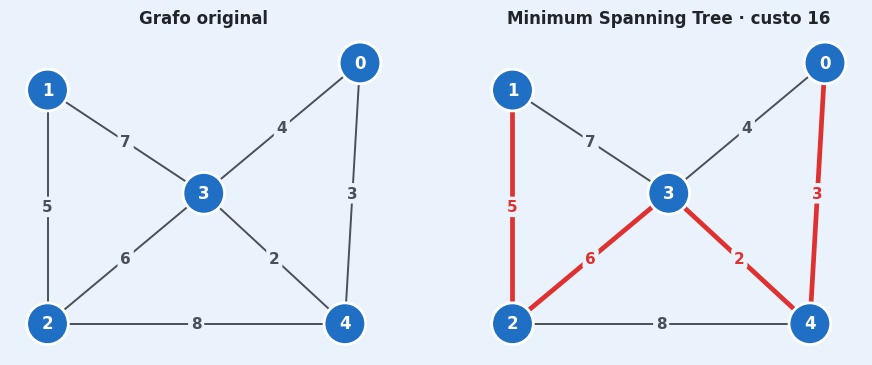

In [13]:
nossa = {frozenset((u, v)) for u, v, _ in mst_toy}
for algoritmo in ["kruskal", "prim", "boruvka"]:
    T = nx.minimum_spanning_tree(G_toy, weight="weight", algorithm=algoritmo)
    mesmas = nossa == {frozenset(e) for e in T.edges()}
    print(f"{algoritmo:<8} custo {T.size(weight='weight'):g} · mesmas arestas que a nossa? {mesmas}")

fig, eixos = plt.subplots(1, 2, figsize=(11, 4.2), facecolor=PALETA["fundo_claro"])
desenhar_grafo(G_toy, POS_TOY, eixos[0], titulo="Grafo original")
desenhar_grafo(G_toy, POS_TOY, eixos[1], mst=mst_toy, titulo=f"Minimum Spanning Tree · custo {custo_toy}")
plt.show()

---
## Parte 4 · Laboratórios

🎯 Mexer no grafo e observar como a MST reage. É aqui que a intuição se forma.

### 🔬 Laboratório 1 · Mude os pesos do grafo dos slides

Cada controle deslizante altera o peso de uma aresta e a MST é recalculada na hora. Os controles ficam agrupados ao lado da figura (proximidade), então você mexe e vê o efeito sem rolar a tela. Tente responder às perguntas abaixo **antes** de mexer e depois confira.

1. Quanto o peso da aresta 0-3 precisa cair para ela entrar na MST? Qual aresta sai quando isso acontece?
2. Se você **aumentar** o peso de uma aresta que **não** está na MST, a MST muda?
3. Coloque duas arestas com o mesmo peso. O que acontece com a unicidade da MST?

In [14]:
PESOS_ORIGINAIS = {(u, v): w for u, v, w in edgeList}
MST_ORIGINAL = {frozenset((u, v)) for u, v, _ in mst_toy}

controles = {f"p_{u}_{v}": widgets.IntSlider(value=w, min=1, max=15, description=f"aresta {u}-{v}",
                                             continuous_update=False,
                                             style={"description_width": "70px"},
                                             layout=widgets.Layout(width="260px"))
             for (u, v), w in sorted(PESOS_ORIGINAIS.items(), key=lambda kv: kv[1])}


def laboratorio_pesos(**pesos):
    arestas = [(int(k.split("_")[1]), int(k.split("_")[2]), w) for k, w in pesos.items()]
    G = nx.Graph()
    G.add_weighted_edges_from(arestas)
    mst, custo = kruskal(G.nodes(), arestas)
    atual = {frozenset((u, v)) for u, v, _ in mst}

    # quantas MSTs diferentes existem com esse custo? (só possível porque o grafo é minúsculo)
    n_otimas = 0
    for T in nx.SpanningTreeIterator(G, weight="weight", minimum=True):
        if T.size(weight="weight") > custo:
            break
        n_otimas += 1

    fig, ax = plt.subplots(figsize=(5.6, 4.3), facecolor=PALETA["fundo_claro"])
    desenhar_grafo(G, POS_TOY, ax, mst=mst, titulo=f"MST · custo {custo}")
    plt.show()
    entrou = [tuple(sorted(e)) for e in atual - MST_ORIGINAL]
    saiu = [tuple(sorted(e)) for e in MST_ORIGINAL - atual]
    print(f"Arestas que entraram em relação à MST original  {entrou or 'nenhuma'}")
    print(f"Arestas que saíram                              {saiu or 'nenhuma'}")
    if n_otimas > 1:
        print(f"⚠️ Há pesos empatados e existem {n_otimas} MSTs diferentes com custo {custo}. "
              "O Kruskal devolve uma delas, conforme a ordem de desempate.")
    else:
        print("A MST é única para esses pesos.")


saida = widgets.interactive_output(laboratorio_pesos, controles)
display(widgets.HBox([widgets.VBox(list(controles.values())), saida]))

<details>
<summary>💬 Respostas comentadas (abra depois de tentar)</summary>

1. A aresta 0-3 compete com o caminho 0-4-3, cujo maior peso é 3. Ela só entra quando o seu peso fica **abaixo de 3**, e aí quem sai é a aresta 0-4, a mais pesada do ciclo 0-3-4. Isso é a **propriedade do ciclo**. Em qualquer ciclo, a aresta estritamente mais pesada nunca está na MST.
2. Não muda. Aumentar o peso de uma aresta que já estava de fora só a deixa ainda menos atraente.
3. Com empates podem existir várias MSTs com o mesmo custo. O **custo** mínimo é sempre único, as **arestas** escolhidas nem sempre.

</details>

### 🔬 Laboratório 2 · Grafos geométricos aleatórios

Agora o grafo é sorteado. Espalhamos $n$ pontos num quadrado e ligamos os pares que estão a uma distância menor que um raio. O peso de cada aresta é a distância euclidiana, como um cabo esticado entre dois prédios. A malha inteira aparece apagada (fundo) e a MST aparece em vermelho (figura).

👀 Diminua o raio até o grafo se partir em pedaços. O Kruskal não quebra. Ele devolve uma **floresta geradora mínima**, uma árvore para cada componente conectada, e cada árvore ganha uma cor diferente (similaridade).

In [15]:
def laboratorio_aleatorio(n=60, raio=0.22, semente=7):
    G = nx.random_geometric_graph(n, raio, seed=semente)
    pos = nx.get_node_attributes(G, "pos")
    for u, v in G.edges():
        G[u][v]["weight"] = math.dist(pos[u], pos[v])        # peso = distância euclidiana
    arestas = [(u, v, d["weight"]) for u, v, d in G.edges(data=True)]
    mst, custo = kruskal(G.nodes(), arestas)
    componentes = list(nx.connected_components(G))
    comp_de = {x: i for i, c in enumerate(sorted(componentes, key=len, reverse=True)) for x in c}

    fig, ax = plt.subplots(figsize=(6.4, 6.4), facecolor="white")
    estilizar_eixo(ax, "white")
    ax.add_collection(LineCollection([[pos[u], pos[v]] for u, v in G.edges()],
                                     colors="#dee2e6", linewidths=0.8, zorder=1))
    ax.add_collection(LineCollection([[pos[u], pos[v]] for u, v, _ in mst],
                                     colors=PALETA["mst"], linewidths=2.4, zorder=2))
    cores = [CORES_GRUPOS[comp_de[x] % len(CORES_GRUPOS)] if len(componentes) > 1 else PALETA["no"] for x in G]
    ax.scatter(*zip(*[pos[x] for x in G]), s=38, c=cores, edgecolors="white", linewidths=0.8, zorder=3)
    ax.set_xlim(-0.02, 1.02); ax.set_ylim(-0.02, 1.02); ax.set_aspect("equal")
    tipo = "árvore geradora mínima" if len(componentes) == 1 else f"floresta geradora mínima ({len(componentes)} árvores)"
    ax.set_title(f"{tipo}\n{G.number_of_edges()} arestas no grafo → {len(mst)} na MST", fontsize=11, fontweight="bold")
    plt.show()

    T_nx = nx.minimum_spanning_tree(G, weight="weight")
    ref = T_nx.size(weight="weight")
    print(f"Custo do nosso Kruskal {custo:.4f} · custo do NetworkX {ref:.4f} · "
          f"{'✔ iguais' if math.isclose(custo, ref) else '✘ diferentes'}")
    print(f"Repare que |MST| = V − (número de componentes) = {n} − {len(componentes)} = {len(mst)}")


ctl_n = widgets.IntSlider(value=60, min=5, max=300, step=5, description="pontos n", continuous_update=False)
ctl_r = widgets.FloatSlider(value=0.22, min=0.05, max=0.6, step=0.01, description="raio", continuous_update=False)
ctl_s = widgets.IntSlider(value=7, min=0, max=50, description="semente", continuous_update=False)
saida2 = widgets.interactive_output(laboratorio_aleatorio, dict(n=ctl_n, raio=ctl_r, semente=ctl_s))
display(widgets.HBox([widgets.VBox([ctl_n, ctl_r, ctl_s]), saida2]))

---
## Parte 5 · Complexidade na prática

🎯 Confirmar no cronômetro o $O(E \log E)$ dos slides e ver o peso da escolha do Union-Find.

🧠 O custo do Kruskal tem duas partes.

* **Ordenar** as $E$ arestas custa $O(E \log E)$.
* **Varrer** as arestas faz $O(E)$ chamadas de `find` e $O(V)$ de `union`. Com o Union-Find otimizado isso é $O(E\,\alpha(V))$, praticamente linear.

Somando, o tempo é $O(E \log E)$, dominado pela ordenação. O espaço é $O(E + V)$, a lista de arestas mais o Union-Find. Mas atenção, essa conta **só vale com um Union-Find bom**. Com o Quick-Find dos rótulos, cada `union` custa $O(V)$ e o total vira $O(E \log E + V^2)$.

O experimento abaixo gera grafos aleatórios com grau médio 8 e cronometra o nosso Kruskal com cada um dos três Union-Find, o Kruskal do NetworkX e, como referência, só a ordenação. Ele leva cerca de meio minuto.

In [16]:
def grafo_aleatorio(n, grau_medio=8, semente=0):
    rng = random.Random(semente)
    G = nx.gnm_random_graph(n, n * grau_medio // 2, seed=semente)
    for u, v in G.edges():
        G[u][v]["weight"] = rng.random()
    return G


def cronometrar(funcao, repeticoes=3):
    melhor = float("inf")
    for _ in range(repeticoes):
        t0 = time.perf_counter()
        funcao()
        melhor = min(melhor, time.perf_counter() - t0)
    return melhor * 1000      # milissegundos


TAMANHOS = [250, 500, 1000, 2000, 4000, 8000, 16000, 32000]
LIMITE_LENTOS = 8000          # acima disso as versões ingênuas levam minutos
resultados = []
for n in TAMANHOS:
    G = grafo_aleatorio(n)
    arestas = [(u, v, d["weight"]) for u, v, d in G.edges(data=True)]
    E = len(arestas)
    linha = dict(V=n, E=E)
    linha["só ordenar"] = cronometrar(lambda: sorted(arestas, key=lambda a: a[2]))
    linha["Union-Find otimizado"] = cronometrar(lambda: kruskal(G.nodes(), arestas, UnionFind))
    if n <= LIMITE_LENTOS:     # uma repetição só, para não esperar demais
        linha["Quick-Union ingênuo"] = cronometrar(lambda: kruskal(G.nodes(), arestas, QuickUnionIngenuo), 1)
        linha["Quick-Find (rótulos)"] = cronometrar(lambda: kruskal(G.nodes(), arestas, QuickFind), 1)
    linha["NetworkX"] = cronometrar(lambda: nx.minimum_spanning_tree(G, algorithm="kruskal"))
    resultados.append(linha)
    print(f"V = {n:>6}  E = {E:>7}  pronto")

df_tempos = pd.DataFrame(resultados)
display(df_tempos.round(1).set_index(["V", "E"]))

V =    250  E =    1000  pronto
V =    500  E =    2000  pronto
V =   1000  E =    4000  pronto
V =   2000  E =    8000  pronto
V =   4000  E =   16000  pronto
V =   8000  E =   32000  pronto
V =  16000  E =   64000  pronto
V =  32000  E =  128000  pronto


,,só ordenar,Union-Find otimizado,Quick-Union ingênuo,Quick-Find (rótulos),NetworkX
V,E,,,,,
250,1000,0.3,1.8,10.6,16.3,5.7
500,2000,0.4,3.8,48.2,61.0,11.6
1000,4000,1.0,4.7,85.6,145.8,14.4
2000,8000,2.1,10.4,420.4,518.0,29.7
4000,16000,4.6,22.2,1811.9,2124.5,66.9
8000,32000,9.9,50.5,8911.6,8153.7,155.9
16000,64000,32.6,185.6,NaN,NaN,404.5
32000,128000,49.7,246.8,NaN,NaN,913.7


In [17]:
CORES_METODOS = {"Union-Find otimizado": PALETA["no"], "Quick-Union ingênuo": "#9c36b5",
                 "Quick-Find (rótulos)": "#e8590c", "NetworkX": "#2f9e44", "só ordenar": "#868e96"}

fig = go.Figure()
for metodo, cor in CORES_METODOS.items():
    dados = df_tempos.dropna(subset=[metodo])
    fig.add_trace(go.Scatter(x=dados["E"], y=dados[metodo], name=metodo, mode="lines+markers",
                             line=dict(color=cor, width=3, dash="dash" if metodo == "só ordenar" else "solid"),
                             marker=dict(size=8),
                             hovertemplate="E = %{x:,}<br>%{y:.1f} ms<extra>" + metodo + "</extra>"))
# curva de referência proporcional a E log E, ajustada no último ponto do Union-Find otimizado
E_ref = df_tempos["E"].to_numpy(dtype=float)
c = df_tempos["Union-Find otimizado"].iloc[-1] / (E_ref[-1] * np.log2(E_ref[-1]))
fig.add_trace(go.Scatter(x=E_ref, y=c * E_ref * np.log2(E_ref), name="referência ∝ E log E",
                         mode="lines", line=dict(color="black", dash="dot", width=1.5), hoverinfo="skip"))
fig.update_layout(title="Tempo do Kruskal em função do número de arestas (escalas logarítmicas)",
                  xaxis=dict(title="número de arestas E", type="log"),
                  yaxis=dict(title="tempo (ms)", type="log"),
                  template="plotly_white", height=480, legend=dict(x=1.02, y=1.0, xanchor="left"))
fig.show()

# contagem de operações elementares num grafo com V = 4000
G = grafo_aleatorio(4000)
arestas = [(u, v, d["weight"]) for u, v, d in G.edges(data=True)]
ops = {}
for Classe in (QuickFind, QuickUnionIngenuo, UnionFind):
    uf = Classe(G.nodes())
    for u, v, w in sorted(arestas, key=lambda a: a[2]):
        uf.union(u, v)
    ops[Classe.nome] = fmt(uf.ops, 0)
painel("Operações elementares do Union-Find no mesmo grafo (V = 4.000, E = 16.000)", ops, cor=PALETA["no"])

👀 **Como ler o gráfico.** Em escala log-log, uma reta com inclinação 1 significa crescimento linear e uma com inclinação 2 significa crescimento quadrático.

* As curvas do **Union-Find otimizado** e do **NetworkX** acompanham a referência $E \log E$, como prometem os slides.
* A linha tracejada **só ordenar** fica abaixo e é **paralela** às outras duas. A ordenação é o termo que domina assintoticamente. Em Python o laço com o Union-Find ainda custa mais do que ela, porque o `sorted` é escrito em C e cada operação de dicionário no laço tem um custo fixo alto, mas os dois crescem no mesmo ritmo.
* O **Quick-Find** sobe com inclinação perto de 2. É o $V^2$ das reescritas de rótulos aparecendo.
* O **Quick-Union ingênuo** é ainda pior. Sem união por tamanho as árvores ficam altas, e sem compressão de caminho cada um dos $E$ `find` percorre de novo essas cadeias compridas. Em grafos maiores ele leva minutos, por isso as duas versões ingênuas param em 8.000 vértices.
* O painel mostra o mesmo fenômeno sem depender do relógio. São milhões de operações nas versões ingênuas contra algumas dezenas de milhares na otimizada.

🧩 **Para pensar.** Num grafo de ruas, $E$ é proporcional a $V$ (cada esquina tem poucas ruas). Num grafo completo entre $k$ pontos de interesse, $E = k(k-1)/2$. Qual dos dois casos vamos encontrar nas Partes 6 e 7?

---
## Parte 6 · Natal I · a malha viária do Tirol

🎯 Rodar o nosso Kruskal num grafo real e interpretar o resultado como um projeto de infraestrutura.

O slide de aplicações mostra o bairro do Tirol com a MST destacada. Vamos refazer essa figura com o seguinte cenário. A prefeitura quer passar fibra óptica **sob as ruas** do Tirol de modo que **todas as esquinas** fiquem ligadas, e cada trecho escavado custa proporcionalmente ao seu comprimento. O menor conjunto de trechos que liga tudo é exatamente a MST do grafo em que

* os vértices são as **interseções** (esquinas),
* as arestas são os **trechos de rua** entre duas interseções,
* o peso é o atributo `length`, o comprimento em metros calculado pelo OSMnx.

🔬 Troque `BAIRRO` por outro bairro de Natal (Petrópolis, Ponta Negra, Lagoa Nova, Alecrim...) e rode a Parte 6 de novo.

In [18]:
LUGAR = "Natal, Rio Grande do Norte, Brazil"
BAIRRO = "Tirol, Natal, Rio Grande do Norte, Brazil"
CENTRO_TIROL = (-5.7975, -35.2065)     # (lat, lon), usado só se a busca pelo nome falhar

try:
    G_bairro_osm = ox.graph_from_place(BAIRRO, network_type="drive")
except Exception as erro:
    print(f"Não encontrei o polígono '{BAIRRO}' ({type(erro).__name__}).")
    print("Usando um raio de 1 km ao redor do centro do Tirol.")
    G_bairro_osm = ox.graph_from_point(CENTRO_TIROL, dist=1000, network_type="drive")

print(G_bairro_osm)

MultiDiGraph with 466 nodes and 881 edges


⚠️ **Três cuidados antes de rodar o Kruskal na malha do OSM.**

1. **Direção.** O OSMnx devolve um `MultiDiGraph`, em que cada rua de mão dupla aparece como **dois arcos**, um em cada sentido. Para cabos e tubulações a mão de direção não importa, então convertemos para não direcionado com `ox.convert.to_undirected`, que reconhece os dois arcos de uma mesma rua e os junta numa única aresta. Uma conversão ingênua, que copia cada arco como aresta, deixaria toda rua de mão dupla duplicada.
2. **Arestas paralelas.** Mesmo sem direção, duas esquinas podem estar ligadas por mais de um trecho (uma rua e uma alça, por exemplo). Para a MST só interessa o mais curto, então montamos um `Graph` simples guardando o menor `length` entre as paralelas. Pegar sempre a aresta de chave `0` de um `MultiGraph` nem sempre devolve a mais curta.
3. **Conectividade.** Recortes de mapa costumam ter pedaços soltos, como um estacionamento ou uma rua cortada pela borda. Ficamos com a **maior componente conectada**, para que exista uma árvore geradora de verdade e não uma floresta.

As funções abaixo cuidam disso e também de desenhar ruas com a sua **geometria real**. Assim as linhas seguem a curva das ruas (continuidade) em vez de cortar quarteirões em linha reta.

In [19]:
def preparar_grafo(G_osm, peso="length"):
    """MultiDiGraph do OSMnx → Graph simples, não direcionado e conectado.
    Devolve o grafo e um dicionário com o número de arestas em cada etapa."""
    etapas = {"arcos no MultiDiGraph do OSM": G_osm.number_of_edges()}
    G_und = ox.convert.to_undirected(G_osm)                         # cuidado 1
    etapas["arestas no MultiGraph não direcionado"] = G_und.number_of_edges()
    H = nx.Graph()
    H.graph.update(G_und.graph)
    H.add_nodes_from(G_und.nodes(data=True))
    for u, v, d in G_und.edges(data=True):                          # cuidado 2
        if u == v:
            continue                                                # laço nunca entra numa árvore
        if not H.has_edge(u, v) or d.get(peso, math.inf) < H[u][v].get(peso, math.inf):
            if H.has_edge(u, v):
                H.remove_edge(u, v)
            H.add_edge(u, v, **d)
    etapas["arestas no Graph simples"] = H.number_of_edges()
    maior = max(nx.connected_components(H), key=len)              # cuidado 3
    H = H.subgraph(maior).copy()
    etapas["arestas na maior componente"] = H.number_of_edges()
    return H, etapas


def nome_rua(d):
    n = d.get("name")
    if isinstance(n, list):
        n = " / ".join(map(str, n))
    if n is None or (isinstance(n, float) and math.isnan(n)) or n == "":
        return "rua sem nome"
    return str(n)


def coords_aresta(H, u, v):
    """Coordenadas (lons, lats) da aresta u-v, seguindo a geometria real e no sentido u → v."""
    d = H[u][v]
    xu, yu = H.nodes[u]["x"], H.nodes[u]["y"]
    if "geometry" in d:
        xs, ys = (list(c) for c in d["geometry"].xy)
        if (xs[0] - xu) ** 2 + (ys[0] - yu) ** 2 > (xs[-1] - xu) ** 2 + (ys[-1] - yu) ** 2:
            xs, ys = xs[::-1], ys[::-1]                             # geometria estava invertida
        return xs, ys
    return [xu, H.nodes[v]["x"]], [yu, H.nodes[v]["y"]]


def coords_rota(H, rota):
    """Concatena as coordenadas de uma rota (lista de nós) numa única polilinha contínua."""
    xs, ys = [], []
    for a, b in zip(rota, rota[1:]):
        x, y = coords_aresta(H, a, b)
        if xs:
            x, y = x[1:], y[1:]
        xs += x
        ys += y
    return xs, ys


def segmento_reto(H, u, v):
    return [H.nodes[u]["x"], H.nodes[v]["x"]], [H.nodes[u]["y"], H.nodes[v]["y"]]


def polilinhas(lista_coords, casas=5):
    """Junta várias polilinhas num único traço do Plotly, separadas por None."""
    X, Y = [], []
    for xs, ys in lista_coords:
        X += [round(x, casas) for x in xs] + [None]
        Y += [round(y, casas) for y in ys] + [None]
    return X, Y


def eixo_mapa(ax, H, titulo="", margem=0.002):
    """Eixo escuro com proporção correta para coordenadas em graus."""
    estilizar_eixo(ax, PALETA["fundo_escuro"])
    xs = [d["x"] for _, d in H.nodes(data=True)]
    ys = [d["y"] for _, d in H.nodes(data=True)]
    ax.set_xlim(min(xs) - margem, max(xs) + margem)
    ax.set_ylim(min(ys) - margem, max(ys) + margem)
    ax.set_aspect(1 / np.cos(np.radians(np.mean(ys))))
    ax.set_title(titulo, color="white", fontsize=12, fontweight="bold")


def desenhar_linhas(ax, lista_coords, cor, lw, alpha=1.0, z=1):
    ax.add_collection(LineCollection([list(zip(xs, ys)) for xs, ys in lista_coords], colors=cor,
                                     linewidths=lw, alpha=alpha, zorder=z, capstyle="round"))


def mapa_base(H, zoom=14):
    """Mapa Folium com dois fundos para alternar (figura e fundo)."""
    lat = float(np.mean([d["y"] for _, d in H.nodes(data=True)]))
    lon = float(np.mean([d["x"] for _, d in H.nodes(data=True)]))
    m = folium.Map(location=[lat, lon], zoom_start=zoom, tiles=None, control_scale=True)
    folium.TileLayer("CartoDB dark_matter", name="fundo escuro").add_to(m)
    folium.TileLayer("CartoDB positron", name="fundo claro").add_to(m)
    return m


def camada_linhas(nome, itens, cor, peso, opacidade=1.0, mostrar=True, traco=None):
    """itens é uma lista de (lons, lats, texto_do_tooltip)."""
    fg = folium.FeatureGroup(name=nome, show=mostrar)
    for xs, ys, dica in itens:
        folium.PolyLine(list(zip(ys, xs)), color=cor, weight=peso, opacity=opacidade,
                        tooltip=dica, dash_array=traco).add_to(fg)
    return fg


H_bairro, etapas = preparar_grafo(G_bairro_osm)
painel("Do OpenStreetMap ao grafo que o Kruskal recebe (número de arestas em cada etapa)",
       {k: fmt(v, 0) for k, v in etapas.items()}, cor=PALETA["no"])

In [20]:
arestas_bairro = [(u, v, d["length"]) for u, v, d in H_bairro.edges(data=True)]

t0 = time.perf_counter()
mst_bairro, custo_bairro = kruskal(H_bairro.nodes(), arestas_bairro)
tempo_ms = (time.perf_counter() - t0) * 1000

# conferência com o NetworkX
T_ref = nx.minimum_spanning_tree(H_bairro, weight="length", algorithm="kruskal")
assert math.isclose(custo_bairro, T_ref.size(weight="length")), "custos diferentes!"
assert len(mst_bairro) == H_bairro.number_of_nodes() - 1

extensao_total = H_bairro.size(weight="length")
painel("MST da malha viária do bairro (conferida com o NetworkX ✔)", {
    "interseções (V)": fmt(H_bairro.number_of_nodes(), 0),
    "trechos de rua (E)": fmt(H_bairro.number_of_edges(), 0),
    "arestas na MST (V − 1)": fmt(len(mst_bairro), 0),
    "extensão de todas as ruas": f"{fmt(extensao_total / 1000, 2)} km",
    "extensão da MST": f"{fmt(custo_bairro / 1000, 2)} km",
    "economia": f"{fmt(100 * (1 - custo_bairro / extensao_total), 1)} %",
    "tempo do Kruskal": f"{fmt(tempo_ms, 1)} ms",
})

### 👀 Três olhares sobre o mesmo bairro

As três figuras abaixo usam exatamente a mesma escala e o mesmo enquadramento (similaridade), então a única coisa que muda é **o que está em primeiro plano**. Na primeira, todas as ruas. Na segunda, a MST vira figura e o resto vira fundo. Na terceira, invertemos o foco e mostramos só os trechos que o Kruskal **descartou**, cada um deles fecharia um ciclo.

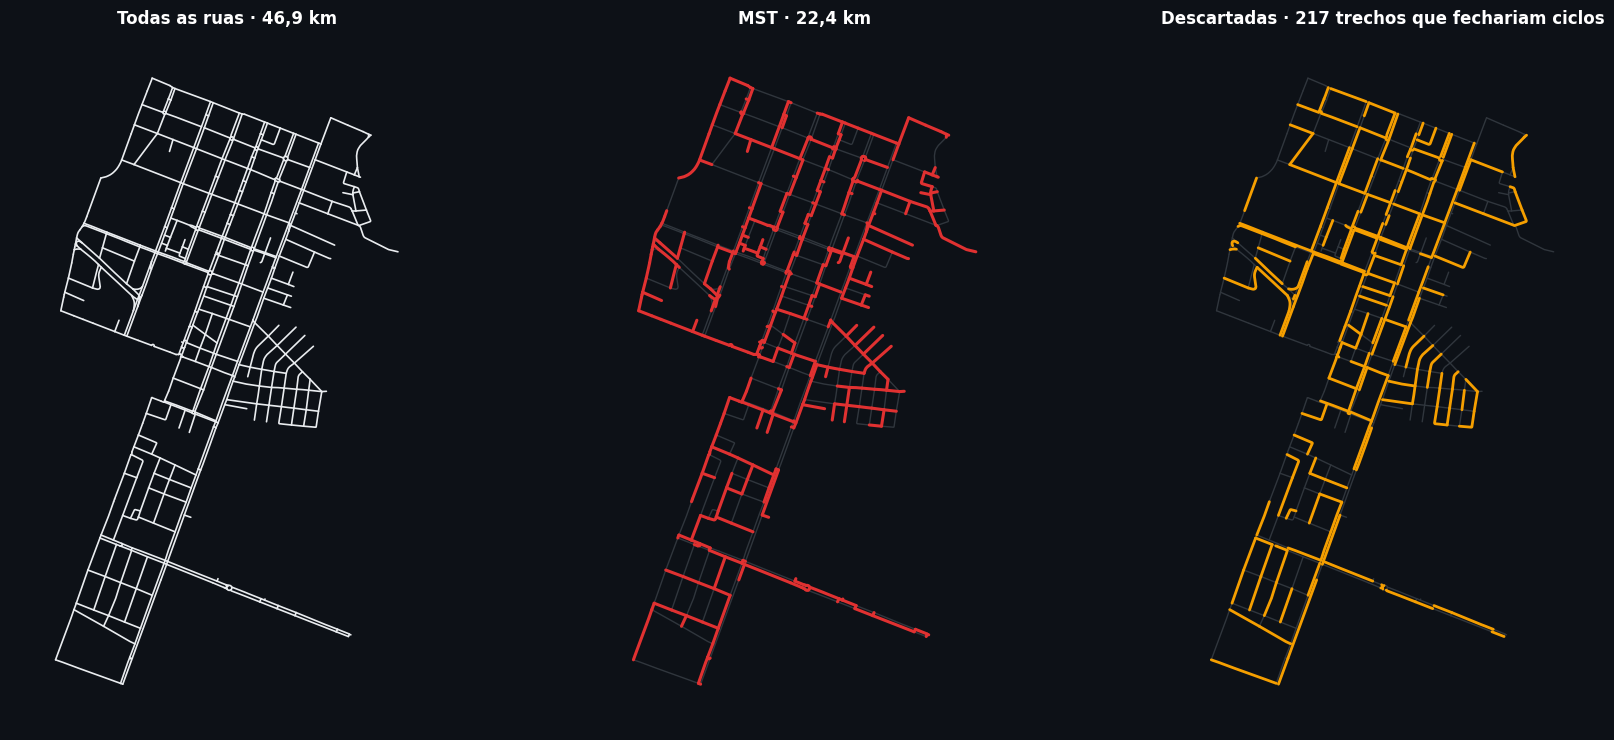

In [21]:
na_mst = {frozenset((u, v)) for u, v, _ in mst_bairro}
c_todas = [coords_aresta(H_bairro, u, v) for u, v in H_bairro.edges()]
c_mst = [coords_aresta(H_bairro, u, v) for u, v, _ in mst_bairro]
c_fora = [coords_aresta(H_bairro, u, v) for u, v in H_bairro.edges() if frozenset((u, v)) not in na_mst]

fig, eixos = plt.subplots(1, 3, figsize=(18, 7.5), facecolor=PALETA["fundo_escuro"])
eixo_mapa(eixos[0], H_bairro, f"Todas as ruas · {fmt(extensao_total / 1000, 1)} km")
desenhar_linhas(eixos[0], c_todas, "#e9ecef", 1.2)

eixo_mapa(eixos[1], H_bairro, f"MST · {fmt(custo_bairro / 1000, 1)} km")
desenhar_linhas(eixos[1], c_todas, PALETA["malha"], 1.0)                 # fundo
desenhar_linhas(eixos[1], c_mst, PALETA["mst"], 2.2, z=2)                 # figura

eixo_mapa(eixos[2], H_bairro, f"Descartadas · {len(c_fora)} trechos que fechariam ciclos")
desenhar_linhas(eixos[2], c_todas, PALETA["malha"], 1.0)
desenhar_linhas(eixos[2], c_fora, PALETA["analise"], 2.0, z=2)
plt.tight_layout()
plt.show()

### 🎬 O Kruskal crescendo pelo bairro

🧠 **O Kruskal cresce em muitos lugares ao mesmo tempo.** Diferente do Prim, que expande uma única árvore a partir de um vértice inicial, o Kruskal só olha para o peso. Os trechos mais curtos estão espalhados pelo bairro inteiro, então surgem muitas **ilhas coloridas** (cada cor é um conjunto do Union-Find) que vão se fundindo até sobrar uma só. Os vértices cinza ainda estão sozinhos. Em âmbar aparecem as arestas que acabaram de entrar.

👀 Repare que os trechos longos entram só no final. Em geral eles são as ligações entre partes do bairro, e é aí que as últimas ilhas se juntam.

In [22]:
def animar_crescimento_geo(H, mst, nos, rotas=None, nomes=None, quadros=None, titulo="",
                           tamanho_no=7, duracao=350, altura=680, base_geometria=False):
    """Animação Plotly da MST crescendo sobre o mapa.

    H        grafo com coordenadas (x = longitude, y = latitude)
    mst      arestas (u, v, w) na ORDEM em que o Kruskal as aceitou
    nos      vértices desenhados como pontos (esquinas ou pontos de interesse)
    rotas    dicionário opcional {(u, v): lista de nós da rota real}
    nomes    dicionário opcional {nó: nome} para o hover
    quadros  número de quadros (None = um quadro por aresta)
    """
    nos = list(nos)
    F = quadros or len(mst)
    limites = np.linspace(0, len(mst), F + 1).round().astype(int)

    def desenho(u, v):
        if rotas is not None:
            return coords_rota(H, rotas[(u, v)])
        return coords_aresta(H, u, v)

    linhas_mst = [desenho(u, v) for u, v, _ in mst]
    fundo = [coords_aresta(H, u, v) if base_geometria else segmento_reto(H, u, v) for u, v in H.edges()]
    bx, by = polilinhas(fundo)
    nx_ = [H.nodes[x]["x"] for x in nos]
    ny_ = [H.nodes[x]["y"] for x in nos]
    hover = [(nomes or {}).get(x, f"nó {x}") for x in nos]

    uf = UnionFind(nos)
    cor_raiz = {}

    def cores_nos():
        raiz = {x: uf.find(x) for x in nos}
        tam = defaultdict(int)
        for r in raiz.values():
            tam[r] += 1
        cores = []
        for x in nos:
            r = raiz[x]
            if tam[r] == 1:
                cores.append(PALETA["isolado"])
            else:
                if r not in cor_raiz:
                    cor_raiz[r] = CORES_GRUPOS_ESCURO[len(cor_raiz) % len(CORES_GRUPOS_ESCURO)]
                cores.append(cor_raiz[r])
        return cores, len(tam)

    quadros_plotly, km = [], 0.0
    for f in range(F + 1):
        ini, fim = (0, 0) if f == 0 else (limites[f - 1], limites[f])
        for u, v, w in mst[ini:fim]:
            uf.union(u, v)
            km += w / 1000
        cores, ncomp = cores_nos()
        ax_, ay_ = polilinhas(linhas_mst[:ini])
        nx2, ny2 = polilinhas(linhas_mst[ini:fim])
        sub = f"{fim} de {len(nos) - 1} arestas · {ncomp} componentes · {fmt(km, 2)} km"
        if nomes and fim - ini == 1:
            u, v, w = mst[ini]
            sub += f" · liga {nomes.get(u, u)[:35]} ↔ {nomes.get(v, v)[:35]}"
        quadros_plotly.append(go.Frame(
            name=str(f), traces=[1, 2, 3],
            layout=go.Layout(title_text=f"{titulo}<br><sup>{sub}</sup>"),
            data=[go.Scatter(x=ax_, y=ay_), go.Scatter(x=nx2, y=ny2),
                  go.Scatter(x=nx_, y=ny_, marker=dict(color=cores))]))

    lat0 = np.mean(ny_)
    fig = go.Figure(
        data=[go.Scatter(x=bx, y=by, mode="lines", line=dict(color=PALETA["malha"], width=1), hoverinfo="skip"),
              go.Scatter(x=[], y=[], mode="lines", line=dict(color=PALETA["mst"], width=3), hoverinfo="skip"),
              go.Scatter(x=[], y=[], mode="lines", line=dict(color=PALETA["analise"], width=6), hoverinfo="skip"),
              go.Scatter(x=nx_, y=ny_, mode="markers", text=hover, hoverinfo="text",
                         marker=dict(size=tamanho_no, color=[PALETA["isolado"]] * len(nos),
                                     line=dict(width=1, color="white")))],
        frames=quadros_plotly)
    fig.update_layout(
        height=altura, showlegend=False, paper_bgcolor=PALETA["fundo_escuro"],
        plot_bgcolor=PALETA["fundo_escuro"], font=dict(color="#e9ecef"),
        title=dict(text=f"{titulo}<br><sup>pressione ▶</sup>", x=0.01), margin=dict(l=10, r=10, t=70, b=10),
        xaxis=dict(visible=False), yaxis=dict(visible=False, scaleanchor="x", scaleratio=1 / np.cos(np.radians(lat0))),
        updatemenus=[dict(type="buttons", direction="left", x=0.0, y=0.0, xanchor="left", yanchor="top",
                          buttons=[dict(label="▶ tocar", method="animate",
                                        args=[None, dict(frame=dict(duration=duracao, redraw=True),
                                                         fromcurrent=True, transition=dict(duration=0))]),
                                   dict(label="⏸ pausar", method="animate",
                                        args=[[None], dict(frame=dict(duration=0, redraw=False), mode="immediate")])])],
        sliders=[dict(active=0, x=0.18, len=0.82, y=0.0, yanchor="top", currentvalue=dict(visible=False),
                      font=dict(color="#e9ecef"),
                      steps=[dict(label=str(f), method="animate",
                                  args=[[str(f)], dict(mode="immediate", frame=dict(duration=0, redraw=True),
                                                       transition=dict(duration=0))])
                             for f in range(F + 1)])])
    return fig


animar_crescimento_geo(H_bairro, mst_bairro, H_bairro.nodes(), quadros=40, base_geometria=True,
                       titulo="Kruskal no bairro · as ilhas coloridas são os conjuntos do Union-Find").show()

### 🛡️ Análise de criticidade

O último item do slide de aplicações é *Critical Infrastructure Analysis*, comparar a MST com a malha original para achar as ruas essenciais. A teoria de grafos dá duas ferramentas precisas para isso.

🧠 **Pontes.** Uma ponte é uma aresta cuja remoção desconecta o grafo. Ela é a única ligação entre duas partes da malha, uma rua **sem alternativa**. Toda ponte pertence obrigatoriamente a **toda** árvore geradora (se ficasse de fora, a árvore não alcançaria o outro lado), e portanto à MST. O código abaixo confere esse teorema na prática.

🧠 **Número ciclomático.** Uma árvore com $V$ vértices tem $V - 1$ arestas. Tudo o que a malha tem além disso, ou seja, $E - V + 1$ arestas, cria ciclos. Esse número conta quantas **rotas alternativas independentes** o bairro oferece. Quanto maior, mais resiliente é a malha a um bloqueio.

No mapa interativo abaixo, use o controle de camadas no canto superior direito para ligar e desligar a malha, a MST e as pontes, ou trocar o fundo escuro pelo claro. Passe o mouse sobre uma rua para ver o nome e o comprimento.

In [23]:
pontes = list(nx.bridges(H_bairro))
pontes_na_mst = all(frozenset(p) in na_mst for p in pontes)
ciclomatico = H_bairro.number_of_edges() - H_bairro.number_of_nodes() + 1

painel("Criticidade da malha do bairro", {
    "pontes (ruas sem alternativa)": len(pontes),
    "todas as pontes estão na MST?": "✔ sim" if pontes_na_mst else "✘ não",
    "número ciclomático E − V + 1": fmt(ciclomatico, 0),
    "trechos fora da MST": fmt(H_bairro.number_of_edges() - len(mst_bairro), 0),
}, cor=PALETA["analise"])

def dica_rua(u, v):
    d = H_bairro[u][v]
    return f"{nome_rua(d)} · {fmt(d['length'], 0)} m"

m = mapa_base(H_bairro, zoom=15)
camada_linhas("malha completa", [(*coords_aresta(H_bairro, u, v), dica_rua(u, v)) for u, v in H_bairro.edges()],
              "#868e96", 2, opacidade=0.6).add_to(m)
camada_linhas("MST (fibra mínima)", [(*coords_aresta(H_bairro, u, v), dica_rua(u, v)) for u, v, _ in mst_bairro],
              PALETA["mst"], 4).add_to(m)
camada_linhas("pontes (ruas críticas)", [(*coords_aresta(H_bairro, u, v), "PONTE · " + dica_rua(u, v)) for u, v in pontes],
              PALETA["analise"], 7).add_to(m)
folium.LayerControl(collapsed=False).add_to(m)
m

---
## Parte 7 · Natal II · a rede mínima entre os hospitais

🎯 Usar o Kruskal num problema em que os vértices não são esquinas, e sim **pontos de interesse** espalhados pela cidade.

Agora a pergunta muda. Queremos ligar **todos os hospitais de Natal** com uma rede (de fibra, de transporte de amostras, de ambulâncias de apoio) que siga as ruas e tenha a menor extensão total. Os hospitais não são vizinhos diretos no grafo de ruas, então precisamos de um passo extra.

🧠 **Fecho métrico.** Construímos um **grafo de interesse** completo em que

* cada vértice é um hospital, ancorado no nó da malha mais próximo dele,
* cada **par** de hospitais vira uma aresta,
* o peso da aresta é o **comprimento do menor caminho pelas ruas** entre eles, calculado com Dijkstra.

O Kruskal roda sobre esse grafo de interesse. Depois, cada aresta escolhida é **desdobrada** de volta na rota real pelas ruas para ser desenhada no mapa.

Primeiro baixamos a malha da cidade inteira. É a etapa mais demorada do notebook, então ela é feita uma única vez e reaproveitada nas Partes 7 a 10.

In [24]:
t0 = time.perf_counter()
G_natal_osm = ox.graph_from_place(LUGAR, network_type="drive")
H_natal, etapas = preparar_grafo(G_natal_osm)
painel(f"Malha viária de Natal pronta em {fmt(time.perf_counter() - t0, 1)} s",
       {"interseções": fmt(H_natal.number_of_nodes(), 0),
        "trechos de rua": fmt(H_natal.number_of_edges(), 0),
        "extensão total": f"{fmt(H_natal.size(weight='length') / 1000, 0)} km"}, cor=PALETA["no"])

In [ ]:
def obter_pois(lugar, tags, limite=None, semente=42):
    """Baixa pontos de interesse do OSM e devolve um DataFrame com nome, lat e lon.
    Polígonos (um hospital desenhado como prédio, por exemplo) viram um ponto interno."""
    gdf = ox.features_from_place(lugar, tags=tags)
    pontos = gdf.geometry.representative_point()     # sempre cai dentro do polígono
    nomes = gdf["name"] if "name" in gdf.columns else pd.Series(index=gdf.index, dtype=object)
    df = pd.DataFrame({"nome": nomes.fillna("(sem nome)").astype(str).to_numpy(),
                       "lat": pontos.y.to_numpy(), "lon": pontos.x.to_numpy()})
    if limite and len(df) > limite:
        df = df.sample(limite, random_state=semente)
    return df.reset_index(drop=True)


def ancorar_pois(H, df):
    """Liga cada ponto de interesse ao nó mais próximo da malha.
    Pontos que caem no mesmo nó são agrupados num único terminal."""
    df = df.copy()
    df["no"] = ox.distance.nearest_nodes(H, X=df["lon"].to_numpy(), Y=df["lat"].to_numpy())
    nomes = df.groupby("no")["nome"].apply(lambda s: " / ".join(sorted(set(s)))).to_dict()
    return df, list(nomes), nomes


df_hosp = obter_pois(LUGAR, {"amenity": "hospital"})
df_hosp, terminais_hosp, nomes_hosp = ancorar_pois(H_natal, df_hosp)

painel("Hospitais encontrados no OpenStreetMap", {
    "registros no OSM": len(df_hosp),
    "terminais distintos na malha": len(terminais_hosp),
    "pares possíveis k(k − 1)/2": fmt(len(terminais_hosp) * (len(terminais_hosp) - 1) // 2, 0),
}, cor=PALETA["no"])
display(df_hosp.head(10))

🧠 **Um detalhe de eficiência que faz diferença.** Com $k$ hospitais existem $k(k-1)/2$ pares. Chamar `nx.shortest_path` para cada par roda $k(k-1)/2$ algoritmos de Dijkstra. Só que **um único** Dijkstra a partir de um hospital já calcula a distância até **todos** os outros de uma vez. Então bastam $k$ execuções, e a rota completa só precisa ser reconstruída para as $k - 1$ arestas que entram na MST. Com 50 hospitais isso significa 50 Dijkstras em vez de 1.225.

In [ ]:
def fecho_metrico(H, terminais, peso="length"):
    """Grafo completo entre os terminais, com peso = menor distância pelas ruas."""
    K = nx.Graph()
    K.add_nodes_from(terminais)
    for i, s in enumerate(terminais):
        dist = nx.single_source_dijkstra_path_length(H, s, weight=peso)   # 1 Dijkstra por terminal
        for t in terminais[i + 1:]:
            if t in dist:
                K.add_edge(s, t, weight=dist[t])
    return K


def rede_mst(H, terminais, peso="length"):
    """Fecho métrico → Kruskal → rotas reais das arestas escolhidas."""
    K = fecho_metrico(H, terminais, peso)
    arestas = [(u, v, d["weight"]) for u, v, d in K.edges(data=True)]
    mst, custo = kruskal(K.nodes(), arestas)
    rotas = {}
    for u, v, _ in mst:
        rota = nx.shortest_path(H, u, v, weight=peso)
        rotas[(u, v)] = rota
    # extensão real, contando uma vez só cada trecho de rua compartilhado por várias rotas
    trechos = {frozenset((a, b)) for r in rotas.values() for a, b in zip(r, r[1:])}
    real = sum(H[a][b]["length"] for a, b in map(tuple, trechos))
    return dict(K=K, mst=mst, custo=custo, rotas=rotas, trechos=trechos, extensao_real=real)


t0 = time.perf_counter()
rede_hosp = rede_mst(H_natal, terminais_hosp)
res_hosp = dict(categoria="Hospitais", terminais=terminais_hosp, nomes=nomes_hosp, **rede_hosp)

T_ref = nx.minimum_spanning_tree(rede_hosp["K"], weight="weight")
assert math.isclose(rede_hosp["custo"], T_ref.size(weight="weight"))

painel(f"Rede mínima entre hospitais (conferida com o NetworkX ✔) em {fmt(time.perf_counter() - t0, 1)} s", {
    "arestas no grafo de interesse": fmt(rede_hosp["K"].number_of_edges(), 0),
    "arestas na MST": len(rede_hosp["mst"]),
    "custo da MST (soma das rotas)": f"{fmt(rede_hosp['custo'] / 1000, 1)} km",
    "extensão real de ruas usadas": f"{fmt(rede_hosp['extensao_real'] / 1000, 1)} km",
    "maior ligação da MST": f"{fmt(max(w for *_, w in rede_hosp['mst']) / 1000, 1)} km",
})

### 👀 O mapa estático

É a figura do último slide, redesenhada com figura e fundo. A malha da cidade fica escura e fina, as rotas da MST seguem as ruas em vermelho e os hospitais aparecem em azul com contorno branco, para se destacarem tanto do fundo quanto das rotas.

In [ ]:
def figura_rede(H, res, titulo, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(8.5, 11), facecolor=PALETA["fundo_escuro"])
    eixo_mapa(ax, H, titulo)
    desenhar_linhas(ax, [segmento_reto(H, u, v) for u, v in H.edges()], "#2b3138", 0.5)
    desenhar_linhas(ax, [coords_rota(H, r) for r in res["rotas"].values()], PALETA["mst"], 2.6, z=2)
    xs = [H.nodes[t]["x"] for t in res["terminais"]]
    ys = [H.nodes[t]["y"] for t in res["terminais"]]
    ax.scatter(xs, ys, s=70, c=PALETA["no"], edgecolors="white", linewidths=1.4, zorder=3)
    ax.legend(handles=[Line2D([0], [0], color=PALETA["mst"], lw=3, label="rotas da MST"),
                       Line2D([0], [0], marker="o", color="none", markerfacecolor=PALETA["no"],
                              markeredgecolor="white", markersize=9, label=res["categoria"].lower())],
              loc="lower right", facecolor="#161b22", edgecolor="#30363d", labelcolor="white")
    return ax


figura_rede(H_natal, res_hosp, f"MST entre hospitais de Natal · {fmt(res_hosp['custo'] / 1000, 1)} km")
plt.show()

### 🎬 Assistindo à rede nascer

Cada quadro acrescenta **uma** aresta da MST, na ordem do Kruskal. Os hospitais mudam de cinza para uma cor quando se juntam a um conjunto, e quando dois conjuntos se fundem o menor adota a cor do maior de uma vez só (destino comum). Passe o mouse sobre um ponto para ver o nome do hospital.

In [ ]:
animar_crescimento_geo(H_natal, res_hosp["mst"], res_hosp["terminais"], rotas=res_hosp["rotas"],
                       nomes=res_hosp["nomes"], tamanho_no=12, duracao=700,
                       titulo="Kruskal ligando os hospitais de Natal").show()

### 🗺️ Mapa interativo

O tamanho de cada hospital é proporcional ao seu **grau na MST**, ou seja, a quantas rotas ele se conecta. Hospitais grandes funcionam como **hubs** da rede, a mesma ideia de centralidade de grau da aula de Hubs. Passe o mouse sobre as rotas para ver a distância de cada ligação.

In [ ]:
def mapa_rede(H, res, zoom=12):
    grau = defaultdict(int)
    for u, v, _ in res["mst"]:
        grau[u] += 1
        grau[v] += 1
    m = mapa_base(H, zoom)
    itens = [(*coords_rota(H, res["rotas"][(u, v)]),
              f"{res['nomes'][u]} ↔ {res['nomes'][v]} · {fmt(w / 1000, 2)} km") for u, v, w in res["mst"]]
    camada_linhas("rotas da MST", itens, PALETA["mst"], 4).add_to(m)
    fg = folium.FeatureGroup(name=res["categoria"].lower())
    for t in res["terminais"]:
        folium.CircleMarker([H.nodes[t]["y"], H.nodes[t]["x"]], radius=4 + 3 * grau[t],
                            color="white", weight=1.5, fill=True, fill_color=PALETA["no"], fill_opacity=0.95,
                            tooltip=f"{res['nomes'][t]} · grau {grau[t]} na MST").add_to(fg)
    fg.add_to(m)
    folium.LayerControl(collapsed=False).add_to(m)
    return m


mapa_rede(H_natal, res_hosp)

🧩 **Pensamento crítico.** O painel mostrou dois números diferentes. O **custo da MST** soma o comprimento das $k - 1$ rotas escolhidas. Só que várias rotas compartilham trechos de rua (repare nas avenidas por onde passam muitas linhas vermelhas), e a **extensão real** conta cada trecho uma vez só. Se o objetivo for instalar cabo, o custo verdadeiro é a extensão real.

E tem mais. Nada obriga a rede a se ramificar apenas nos hospitais. Uma rede que pode usar **qualquer esquina** como ponto de junção é uma **Árvore de Steiner**, um problema NP-difícil. A MST sobre o fecho métrico é uma aproximação clássica dele, com garantia de no máximo o dobro do ótimo. O desafio resolvido R2 compara as duas.

---
## Parte 8 · Laboratório da cidade

🎯 Repetir o pipeline inteiro para qualquer tipo de lugar, com um clique.

Os ícones do último slide sugerem outras aplicações, como roteiros turísticos (Tripadvisor), pontos de recarga de veículos elétricos e universidades. O laboratório abaixo junta todas as etapas da Parte 7 numa função só.

🔬 **Como usar.** Escolha uma categoria, defina o número máximo de pontos e clique em **Executar**. Se quiser outra categoria do OpenStreetMap, escreva uma tag no formato `chave=valor` (por exemplo `amenity=police`, `leisure=park` ou `shop=supermarket`) e ela tem prioridade sobre a lista. A lista completa de tags está no [wiki do OSM](https://wiki.openstreetmap.org/wiki/Map_features).

⚠️ O custo cresce com $k^2$ pares e $k$ Dijkstras na cidade inteira. Até uns 100 pontos a resposta vem em segundos. Categorias muito numerosas, como escolas, são amostradas.

In [ ]:
CATEGORIAS = {
    "🏥 Hospitais": {"amenity": "hospital"},
    "🏫 Escolas": {"amenity": "school"},
    "🎓 Universidades e faculdades": {"amenity": ["university", "college"]},
    "💊 Farmácias": {"amenity": "pharmacy"},
    "⚡ Recarga de veículos elétricos": {"amenity": "charging_station"},
    "🏛️ Museus e atrações turísticas": {"tourism": ["museum", "attraction"]},
    "🚌 Terminais de ônibus": {"amenity": "bus_station"},
    "⛽ Postos de combustível": {"amenity": "fuel"},
}
CACHE_POIS = {}
ULTIMO_RESULTADO = None


def laboratorio_cidade(categoria, max_pontos=60, tag_personalizada="", animacao=False):
    global ULTIMO_RESULTADO
    if tag_personalizada.strip():
        chave, _, valor = tag_personalizada.partition("=")
        tags, nome = {chave.strip(): valor.strip() or True}, tag_personalizada.strip()
    else:
        tags, nome = CATEGORIAS[categoria], categoria
    t0 = time.perf_counter()
    try:
        chave_cache = (nome, str(tags))
        if chave_cache not in CACHE_POIS:
            CACHE_POIS[chave_cache] = obter_pois(LUGAR, tags)
        df = CACHE_POIS[chave_cache]
    except Exception as erro:
        print(f"Nenhum lugar encontrado para '{nome}' em Natal ({type(erro).__name__}).")
        return
    if len(df) > max_pontos:
        print(f"{len(df)} registros no OSM, usando uma amostra de {max_pontos}.")
        df = df.sample(max_pontos, random_state=42)
    df, terminais, nomes = ancorar_pois(H_natal, df)
    if len(terminais) < 2:
        print("Pontos insuficientes para formar uma árvore (menos de 2 terminais).")
        return
    rede = rede_mst(H_natal, terminais)
    res = dict(categoria=nome, terminais=terminais, nomes=nomes, **rede)
    ULTIMO_RESULTADO = res
    painel(f"{nome} · pronto em {fmt(time.perf_counter() - t0, 1)} s", {
        "terminais": len(terminais),
        "pares no fecho métrico": fmt(rede["K"].number_of_edges(), 0),
        "custo da MST": f"{fmt(rede['custo'] / 1000, 1)} km",
        "extensão real": f"{fmt(rede['extensao_real'] / 1000, 1)} km",
        "maior ligação (gargalo)": f"{fmt(max(w for *_, w in rede['mst']) / 1000, 2)} km",
    })
    if animacao:
        animar_crescimento_geo(H_natal, res["mst"], terminais, rotas=res["rotas"], nomes=nomes,
                               tamanho_no=11, duracao=600, titulo=f"Kruskal · {nome}").show()
    display(mapa_rede(H_natal, res))


interact_manual(
    laboratorio_cidade,
    categoria=widgets.Dropdown(options=list(CATEGORIAS), value="⚡ Recarga de veículos elétricos",
                               description="categoria", layout=widgets.Layout(width="420px")),
    max_pontos=widgets.IntSlider(value=60, min=5, max=150, step=5, description="máx. pontos"),
    tag_personalizada=widgets.Text(value="", placeholder="ex.: amenity=police", description="tag OSM"),
    animacao=widgets.Checkbox(value=False, description="mostrar animação"),
);

---
## Parte 9 · Agrupamento, cortando a MST em regiões

🎯 Descobrir uma aplicação da MST que não tem nada a ver com construir redes.

🧠 Suponha que a Secretaria de Saúde queira dividir os hospitais de Natal em $k$ **regiões de atendimento**, com hospitais próximos entre si na mesma região. Há uma solução elegante. Pegue a MST e **remova as $k - 1$ arestas mais longas**. A árvore se parte em exatamente $k$ pedaços, e cada pedaço é uma região. Esse método se chama **agrupamento hierárquico por ligação simples** (*single-linkage clustering*), e o Kruskal o calcula de graça, porque parar o algoritmo quando faltam $k - 1$ arestas dá o mesmo resultado.

Por que funciona? As arestas mais longas da MST são justamente as que atravessam os maiores **vazios** entre grupos de pontos. Cortá-las separa os grupos naturais.

👀 Arraste o controle de $k$. Cada região ganha um contorno sombreado (**região comum**) e uma cor própria (**similaridade**). As ligações cortadas aparecem como pontilhado cinza. Quando uma região se divide, a parte maior **mantém a cor** e só a parte nova ganha cor nova, para o olho acompanhar a divisão sem se perder.

In [ ]:
def grupos_por_corte(res, k):
    """Remove as k − 1 arestas mais longas da MST e devolve (grupos, arestas cortadas, mantidas)."""
    por_peso = sorted(res["mst"], key=lambda a: -a[2])
    cortadas, mantidas = por_peso[:k - 1], por_peso[k - 1:]
    uf = UnionFind(res["terminais"])
    for u, v, _ in mantidas:
        uf.union(u, v)
    return list(uf.conjuntos().values()), cortadas, mantidas


def animar_agrupamento(H, res, k_max=8, altura=720):
    terminais = res["terminais"]
    k_max = min(k_max, len(terminais), len(CORES_GRUPOS_ESCURO))
    lat0 = np.mean([H.nodes[t]["y"] for t in terminais])
    bx, by = polilinhas([segmento_reto(H, u, v) for u, v in H.edges()])

    cor_terminal = {t: 0 for t in terminais}       # índice de cor de cada terminal
    proxima_cor = 1
    quadros = []
    for k in range(1, k_max + 1):
        grupos, cortadas, mantidas = grupos_por_corte(res, k)
        if k > 1:   # cores estáveis, a parte maior herda a cor do grupo de onde saiu
            por_pai = defaultdict(list)
            for g in grupos:
                por_pai[cor_terminal[g[0]]].append(g)
            nova = {}
            for c, gs in por_pai.items():
                for j, g in enumerate(sorted(gs, key=len, reverse=True)):
                    if j == 0:
                        cc = c
                    else:
                        cc, proxima_cor = proxima_cor, proxima_cor + 1
                    for t in g:
                        nova[t] = cc
            cor_terminal = nova
        grupos = sorted(grupos, key=lambda g: cor_terminal[g[0]])
        grupo_de = {t: i for i, g in enumerate(grupos) for t in g}

        dados = []
        for slot in range(k_max):                    # contornos sombreados (região comum)
            if slot < len(grupos):
                g = grupos[slot]
                cor = CORES_GRUPOS_ESCURO[cor_terminal[g[0]] % len(CORES_GRUPOS_ESCURO)]
                casca = MultiPoint([(H.nodes[t]["x"], H.nodes[t]["y"]) for t in g]).convex_hull.buffer(0.004)
                hx, hy = (list(c) for c in casca.exterior.xy)
                rgb = tuple(int(cor[i:i + 2], 16) for i in (1, 3, 5))
                dados.append(go.Scatter(x=hx, y=hy, fill="toself", fillcolor=f"rgba{rgb + (0.16,)}",
                                        line=dict(color=cor, width=1.5)))
            else:
                dados.append(go.Scatter(x=[], y=[]))
        for slot in range(k_max):                    # rotas internas de cada região
            if slot < len(grupos):
                g = set(grupos[slot])
                cor = CORES_GRUPOS_ESCURO[cor_terminal[grupos[slot][0]] % len(CORES_GRUPOS_ESCURO)]
                rx, ry = polilinhas([coords_rota(H, res["rotas"][(u, v)]) for u, v, _ in mantidas if u in g])
                dados.append(go.Scatter(x=rx, y=ry, line=dict(color=cor, width=3)))
            else:
                dados.append(go.Scatter(x=[], y=[]))
        cx, cy = polilinhas([segmento_reto(H, u, v) for u, v, _ in cortadas])
        dados.append(go.Scatter(x=cx, y=cy))         # ligações cortadas
        dados.append(go.Scatter(                     # terminais coloridos pela região
            x=[H.nodes[t]["x"] for t in terminais], y=[H.nodes[t]["y"] for t in terminais],
            text=[f"{res['nomes'][t]} · região {grupo_de[t] + 1}" for t in terminais],
            marker=dict(color=[CORES_GRUPOS_ESCURO[cor_terminal[t] % len(CORES_GRUPOS_ESCURO)] for t in terminais])))
        tamanhos = " · ".join(str(len(g)) for g in grupos)
        corte = f"cortamos as {k - 1} ligações mais longas" if k > 1 else "a MST inteira é uma única região"
        quadros.append(go.Frame(name=str(k), traces=list(range(1, 2 * k_max + 3)), data=dados,
                                layout=go.Layout(title_text=f"k = {k} regiões · {corte}<br><sup>tamanhos {tamanhos}</sup>")))

    fig = go.Figure(
        data=[go.Scatter(x=bx, y=by, mode="lines", line=dict(color=PALETA["malha"], width=0.8), hoverinfo="skip")]
             + [go.Scatter(x=[], y=[], mode="lines", hoverinfo="skip") for _ in range(2 * k_max)]
             + [go.Scatter(x=[], y=[], mode="lines", line=dict(color="#adb5bd", width=2, dash="dot"), hoverinfo="skip"),
                go.Scatter(x=[], y=[], mode="markers", hoverinfo="text",
                           marker=dict(size=12, line=dict(width=1.5, color="white")))],
        frames=quadros)
    fig.update_layout(
        height=altura, showlegend=False, paper_bgcolor=PALETA["fundo_escuro"], plot_bgcolor=PALETA["fundo_escuro"],
        font=dict(color="#e9ecef"), margin=dict(l=10, r=10, t=70, b=10), title=dict(x=0.01),
        xaxis=dict(visible=False), yaxis=dict(visible=False, scaleanchor="x", scaleratio=1 / np.cos(np.radians(lat0))),
        sliders=[dict(active=0, currentvalue=dict(prefix="k = ", font=dict(size=14)), font=dict(color="#e9ecef"),
                      pad=dict(t=10), steps=[dict(label=str(k), method="animate",
                                                  args=[[str(k)], dict(mode="immediate", frame=dict(duration=0, redraw=True),
                                                                       transition=dict(duration=0))])
                                             for k in range(1, k_max + 1)])])
    # aplica o primeiro quadro como estado inicial
    for i, tr in zip(quadros[0].traces, quadros[0].data):
        fig.data[i].update(tr)
    fig.layout.title.text = quadros[0].layout.title.text
    return fig


animar_agrupamento(H_natal, res_hosp, k_max=8).show()

🔬 Escolha um valor de $k$ e veja quais hospitais caíram em cada região. Para agrupar o resultado do Laboratório da Parte 8, troque `res_hosp` por `ULTIMO_RESULTADO` nas duas células.

⚠️ **Limitação conhecida.** O agrupamento por ligação simples sofre com o **efeito corrente**. Uma fileira de pontos próximos ao longo de uma avenida pode ligar duas regiões que, no conjunto, estão longe uma da outra. Por isso às vezes surge uma região enorme e várias regiões com um único hospital. Métodos como k-means ou k-medoids equilibram melhor os tamanhos, mas não têm a garantia de separação máxima que o corte da MST oferece.

In [ ]:
def resumo_grupos(res, k):
    grupos, cortadas, _ = grupos_por_corte(res, k)
    linhas = [{"região": i + 1, "hospitais": len(g),
               "nomes": "; ".join(sorted(res["nomes"][t] for t in g))[:160]}
              for i, g in enumerate(sorted(grupos, key=len, reverse=True))]
    display(pd.DataFrame(linhas).set_index("região"))
    if cortadas:
        print(f"Menor ligação cortada {fmt(min(w for *_, w in cortadas) / 1000, 2)} km. "
              "Todo par de regiões fica separado por pelo menos essa distância pelas ruas.")


widgets.interact(lambda k: resumo_grupos(res_hosp, k),
                 k=widgets.IntSlider(value=4, min=1, max=min(10, len(res_hosp["terminais"])), description="k regiões"));

---
## Parte 10 · Desafios

Os três primeiros já vêm **resolvidos**, para você estudar a solução e modificar. Os cinco seguintes ficam **em aberto**, com dicas.

### ✅ R1 · Árvore geradora máxima

Em algumas redes queremos a árvore de **maior** peso. Por exemplo, ligar todos os prédios usando os enlaces de maior largura de banda, ou montar uma rede de rotas com as ruas mais largas. Basta percorrer as arestas em ordem **decrescente**, o que é o mesmo que rodar o Kruskal com os pesos trocados de sinal.

In [ ]:
arestas_negativas = [(u, v, -w) for u, v, w in edgeList]
mst_max, custo_neg = kruskal(G_toy.nodes(), arestas_negativas)
mst_max = [(u, v, -w) for u, v, w in mst_max]

T_max = nx.maximum_spanning_tree(G_toy, weight="weight")
print(f"Nosso Kruskal com pesos negativos · custo {-custo_neg}")
print(f"nx.maximum_spanning_tree           · custo {T_max.size(weight='weight'):g}")

fig, eixos = plt.subplots(1, 2, figsize=(11, 4.2), facecolor=PALETA["fundo_claro"])
desenhar_grafo(G_toy, POS_TOY, eixos[0], mst=mst_toy, titulo=f"Árvore geradora MÍNIMA · {custo_toy}")
desenhar_grafo(G_toy, POS_TOY, eixos[1], mst=mst_max, titulo=f"Árvore geradora MÁXIMA · {-custo_neg}")
plt.show()

### ✅ R2 · MST no fecho métrico × Árvore de Steiner

O NetworkX tem uma aproximação para a Árvore de Steiner, `nx.algorithms.approximation.steiner_tree`, com o método de Mehlhorn. Ela pode criar junções em **qualquer esquina** da cidade, não só nos hospitais. A célula compara três números, o custo da MST somando rotas, a extensão real das ruas que essas rotas usam e a extensão da árvore de Steiner. No mapa, ligue e desligue as camadas para ver onde as duas redes discordam.

In [ ]:
t0 = time.perf_counter()
steiner = nx.algorithms.approximation.steiner_tree(H_natal, res_hosp["terminais"], weight="length", method="mehlhorn")
km_steiner = steiner.size(weight="length") / 1000

painel(f"Três maneiras de medir a rede entre hospitais (Steiner em {fmt(time.perf_counter() - t0, 1)} s)", {
    "MST no fecho métrico (soma das rotas)": f"{fmt(res_hosp['custo'] / 1000, 1)} km",
    "extensão real das rotas da MST": f"{fmt(res_hosp['extensao_real'] / 1000, 1)} km",
    "árvore de Steiner (Mehlhorn)": f"{fmt(km_steiner, 1)} km",
}, cor=PALETA["analise"])

m = mapa_base(H_natal, zoom=12)
camada_linhas("rotas da MST", [(*coords_rota(H_natal, r), "MST") for r in res_hosp["rotas"].values()],
              PALETA["mst"], 5, opacidade=0.8).add_to(m)
camada_linhas("árvore de Steiner", [(*coords_aresta(H_natal, u, v), "Steiner") for u, v in steiner.edges()],
              "#3bc9db", 3).add_to(m)
folium.LayerControl(collapsed=False).add_to(m)
m

👀 A árvore de Steiner em geral fica **mais curta** que a extensão real da MST, porque aproveita esquinas intermediárias como pontos de ramificação. A MST no fecho métrico é uma aproximação com fator 2. O método de Mehlhorn tem a mesma garantia teórica, mas costuma se sair melhor na prática.

### ✅ R3 · Distância ou tempo de viagem?

Até aqui o peso foi o **comprimento**. Para uma rede de ambulâncias faz mais sentido o **tempo de viagem**. O OSMnx usa o limite de velocidade cadastrado em cada rua e, quando ele falta, uma velocidade padrão pelo tipo de via (`ox.routing.add_edge_speeds`). Depois calcula o tempo de cada trecho (`ox.routing.add_edge_travel_times`). Basta trocar o peso e rodar tudo de novo.

In [ ]:
# velocidades usadas quando a rua não tem limite cadastrado no OSM (km/h), inspiradas no
# art. 61 do CTB, 80 em vias de trânsito rápido, 60 em arteriais, 40 em coletoras e 30 em locais
VELOCIDADES = {"motorway": 80, "trunk": 80, "primary": 60, "secondary": 50, "tertiary": 40,
               "unclassified": 30, "residential": 30, "living_street": 20, "service": 20}
G_tempo_osm = ox.routing.add_edge_speeds(G_natal_osm, hwy_speeds=VELOCIDADES, fallback=30)
G_tempo_osm = ox.routing.add_edge_travel_times(G_tempo_osm)
H_tempo, _ = preparar_grafo(G_tempo_osm, peso="travel_time")
terminais_t = [t for t in res_hosp["terminais"] if t in H_tempo]
rede_tempo = rede_mst(H_tempo, terminais_t, peso="travel_time")

pares_dist = {frozenset((u, v)) for u, v, _ in res_hosp["mst"]}
pares_tempo = {frozenset((u, v)) for u, v, _ in rede_tempo["mst"]}
painel("A MST muda quando o critério muda?", {
    "ligações iguais nas duas MSTs": len(pares_dist & pares_tempo),
    "só na MST por distância": len(pares_dist - pares_tempo),
    "só na MST por tempo": len(pares_tempo - pares_dist),
    "tempo total da MST por tempo": f"{fmt(rede_tempo['custo'] / 60, 1)} min",
}, cor=PALETA["analise"])

m = mapa_base(H_natal, zoom=12)
camada_linhas("MST por distância", [(*coords_rota(H_natal, r), "por distância") for r in res_hosp["rotas"].values()],
              PALETA["mst"], 6, opacidade=0.75).add_to(m)
camada_linhas("MST por tempo de viagem", [(*coords_rota(H_tempo, r), "por tempo") for r in rede_tempo["rotas"].values()],
              "#3bc9db", 3).add_to(m)
folium.LayerControl(collapsed=False).add_to(m)
m

👀 Quando o peso vira tempo, rotas por avenidas rápidas ganham das ruas locais mais curtas, e algumas ligações da árvore mudam de par. Mesmo problema, mesma estrutura de dados, outra pergunta e outra resposta.

---

### 🧩 A1 · Carregadores de carro elétrico e o gargalo da MST

Rode o Laboratório da Parte 8 com a categoria de recarga de veículos elétricos.

1. Quantos carregadores o OSM registra em Natal? O mapa parece completo?
2. A **maior aresta da MST** é o maior trecho que um carro precisa percorrer entre dois carregadores vizinhos da rede. Pela **propriedade minimax**, nenhuma outra árvore tem uma maior aresta menor do que essa. Por quê?
3. Se você pudesse instalar 3 novos carregadores, onde eles mais reduziriam esse gargalo?

> Dica. Use `ULTIMO_RESULTADO["mst"]` e ordene por peso. Teste candidatos nos pontos médios das rotas mais longas.

In [ ]:
# 🧩 A1 · seu código aqui

### 🧩 A2 · De árvore a roteiro turístico

Uma MST **não é um roteiro**. Ela tem bifurcações, e um turista não se teletransporta de volta ao início de um galho. Transforme a MST das atrações turísticas num passeio que visita todas.

> Dica. Percorra a árvore em pré-ordem (DFS) a partir de um ponto e vá sempre direto ao próximo vértice ainda não visitado. Esse é o algoritmo de **aproximação 2 para o Caixeiro Viajante** métrico. Compare o comprimento do seu passeio com `nx.approximation.traveling_salesman_problem` aplicado ao fecho métrico.

In [ ]:
# 🧩 A2 · seu código aqui

### 🧩 A3 · Expansão urbana

Um loteamento novo com 6 pontos precisa ser ligado à rede de fibra existente (a MST do Tirol, por exemplo) com o menor custo adicional.

> Dica. Inicialize o Union-Find com **toda a rede existente já unida** num conjunto só e rode o Kruskal apenas com as arestas candidatas novas. Por que isso dá a resposta ótima? Pense na propriedade do corte.

In [ ]:
# 🧩 A3 · seu código aqui

### 🧩 A4 · Qual bairro tem a malha mais redundante?

Calcule, para Tirol, Petrópolis, Ponta Negra, Lagoa Nova e Alecrim, a razão entre a extensão da MST e a extensão total de ruas, e também o número ciclomático por km de rua.

> Dica. Quanto menor a razão, mais ruas sobram além da árvore, ou seja, mais rotas alternativas. Relacione o resultado com o desenho urbano de cada bairro (traçado em xadrez ou ruas sinuosas) e com o mapa de pontes da Parte 6. Monte um gráfico de barras com o Plotly para comparar.

In [ ]:
# 🧩 A4 · seu código aqui

### 🧩 A5 · Vale a pena parar cedo?

Meça o tempo do `kruskal` com `parar_cedo=True` e `parar_cedo=False` na malha de Natal inteira.

> Dica. Descubra em que posição da lista ordenada aparece a **última** aresta aceita. O que isso revela sobre a distribuição dos comprimentos dos trechos de rua? Um histograma dos pesos com a posição de corte marcada ajuda muito.

In [ ]:
# 🧩 A5 · seu código aqui

---
## 🧭 Síntese

| | Kruskal em uma linha |
|---|---|
| **Ideia** | percorrer as arestas da mais leve à mais pesada e aceitar cada uma que não feche ciclo |
| **Estrutura de dados** | Union-Find com união por tamanho e compressão de caminho, que responde *estão no mesmo conjunto?* em tempo praticamente constante |
| **Correção** | propriedade do corte, a aresta mais leve que atravessa um corte é sempre segura |
| **Complexidade** | $O(E \log E)$ de tempo, dominado pela ordenação, e $O(E + V)$ de espaço |
| **Resultado** | $V - 1$ arestas num grafo conectado, ou uma floresta geradora mínima se ele estiver partido |
| **Aplicações vistas** | fibra sob as ruas, ruas críticas (pontes), rede entre hospitais, laboratório de categorias, regiões de atendimento por corte da MST, gargalo minimax |

**Para levar da aula.**

* Uma boa estrutura de dados muda a classe de complexidade. O mesmo Kruskal com Quick-Find é quadrático.
* Modelar é metade do trabalho. Esquinas e trechos de rua respondem uma pergunta, o fecho métrico entre pontos de interesse responde outra.
* Toda resposta de algoritmo merece pensamento crítico. A MST não é um roteiro, não é uma Árvore de Steiner e muda quando o peso muda.

---
<sub>Notebook da disciplina DCA3702 · DCA/UFRN · Conect2ai. Dados de mapas © colaboradores do OpenStreetMap, licença ODbL.</sub>